# VaR y ES del S&P 500: simulación histórica, backtesting y elicitabilidad conjunta (Fissler y Ziegel, 2016)

Este notebook estima el valor en riesgo (VaR) y el *expected shortfall* (ES) diarios de SPY, el ETF que replica el S&P 500, con dos modelos tradicionales: simulación histórica (HS) y normal paramétrico. Luego los evalúa de dos maneras que responden preguntas distintas:

1. **Calibración absoluta del VaR** (Kupiec y Christoffersen). Es una prueba de hipótesis sobre un solo modelo: ¿la tasa de excepciones es igual a $\alpha$ y las excepciones son independientes?
2. **Ranking de modelos con una función de scoring estrictamente consistente para el par (VaR, ES).** El ES no es 1-elicitable de forma aislada, pero el par $(\mathrm{VaR}_\alpha, \mathrm{ES}_\alpha)$ sí es 2-elicitable (Fissler y Ziegel, 2016, Corolario 5.5). Eso permite ordenar modelos según el score promedio y contrastar las diferencias con Diebold-Mariano.

**Cómo leer el notebook.** Los bloques marcados como **Resultado teórico** son propiedades matemáticas que no dependen de los datos. Los marcados como **Hallazgo empírico** son resultados de esta muestra y pueden cambiar con otro activo, periodo o ventana. Cada fórmula aparece antes de su implementación y cada tabla o gráfica tiene su interpretación debajo.

**Contenido**

1. Datos y preparación
2. Estimación tradicional del VaR y ES: simulación histórica
3. Backtesting del VaR: calibración absoluta
4. Evaluación conjunta del VaR y ES
   - 4.1 Marco formal de elicitabilidad
   - 4.2 Imposibilidad del ES aislado
   - 4.3 Elicitabilidad conjunta de (VaR, ES): Corolario 5.5
   - 4.4 Principio de Osband y función de identificación
   - 4.5 Score FZ0: implementación y M-estimación
   - 4.6 Segundo modelo: normal paramétrico
   - 4.7 Ranking de modelos con Diebold-Mariano
5. Resultados y conclusiones

Las referencias están al final.

### Configuración

| Parámetro | Valor | Justificación |
|---|---|---|
| `TICKER` | SPY | ETF líquido sobre el S&P 500. Su precio ajustado incorpora dividendos. |
| `START`, `END` | 2010-01-01, 2026-01-01 | `END` es exclusivo en `yfinance`: la última observación es el 2025-12-31. Son 16 años, que incluyen 2018, la caída de marzo de 2020, 2022 y abril de 2025. |
| `OOS_START` | 2016-01-01 | Separa 6 años de estimación de 10 años de evaluación fuera de muestra. |
| `WINDOW` | 500 | Unos dos años hábiles. Una ventana más larga estima mejor la cola, pero reacciona más tarde a los cambios de volatilidad. |
| `LEVELS` | $\alpha = 0{,}05;\ 0{,}01$ | Probabilidad de cola. Equivale a niveles de confianza de 95 % y 99 %, que es como se rotulan tablas y gráficas. |
| `FORCE_DOWNLOAD` | `False` | Usa la copia local de los datos para que los resultados sean reproducibles. |

En todo el notebook, $\alpha$ es la probabilidad de cola: la tasa de excepciones que promete el VaR. La función `nivel(a)` solo convierte $\alpha$ en la etiqueta de confianza ("95%", "99%"). La semilla `rng` fija las simulaciones de Monte Carlo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import ScalarFormatter
from scipy import integrate, optimize, stats
from scipy.special import xlogy

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
C_HS, C_N, C_L = "#1f4e79", "#c55a11", "#7f7f7f"

TICKER = "SPY"
START, END = "2010-01-01", "2026-01-01"
OOS_START = "2016-01-01"
WINDOW = 500
LEVELS = (0.05, 0.01)
DATA_FILE = Path("data") / "spy_2010_2025.csv"
FORCE_DOWNLOAD = False
rng = np.random.default_rng(2016)


def nivel(a):
    return f"{round(100 * (1 - a), 2):g}%"

## 1. Datos y preparación

### 1.1 Descarga y control de calidad

Se usa el precio de cierre **ajustado** (`auto_adjust=True`), que corrige por dividendos y divisiones de acciones. Así, el rendimiento de un día refleja el retorno total de quien mantiene el ETF y no muestra caídas artificiales en las fechas de pago de dividendos.

Yahoo Finance puede recalcular retroactivamente los precios ajustados. Por eso la primera descarga se guarda en `data/spy_2010_2025.csv` y las ejecuciones posteriores leen ese archivo. Con `FORCE_DOWNLOAD = True` se descargan los datos de nuevo.

In [2]:
def load_prices(path=DATA_FILE, force=FORCE_DOWNLOAD):
    if path.exists() and not force:
        return pd.read_csv(path, index_col="Date", parse_dates=True)
    import yfinance as yf
    df = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False, actions=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df.index.name = "Date"
    path.parent.mkdir(exist_ok=True)
    df.to_csv(path)
    return df


px = load_prices()
price = px["Close"].rename(TICKER)
pd.Series({
    "Primera fecha": price.index.min().date(),
    "Última fecha": price.index.max().date(),
    "Días hábiles": len(price),
    "Faltantes": int(price.isna().sum()),
    "Fechas duplicadas": int(price.index.duplicated().sum()),
    "Precios no positivos": int((price <= 0).sum()),
    "Máx. días calendario entre observaciones": int(price.index.to_series().diff().dt.days.max()),
}, name="Control de calidad").to_frame()

,Control de calidad
Primera fecha,2010-01-04
Última fecha,2025-12-31
Días hábiles,4024
Faltantes,0
Fechas duplicadas,0
Precios no positivos,0
Máx. días calendario entre observaciones,5


La serie tiene 4.024 cierres diarios, sin faltantes, duplicados ni precios no positivos. El mayor salto entre observaciones consecutivas es de 5 días calendario: corresponde al cierre del mercado por el huracán Sandy (del 26 al 31 de octubre de 2012). No hay huecos que distorsionen los rendimientos diarios.

### 1.2 Rendimientos, pérdidas y muestras

El rendimiento logarítmico diario, en porcentaje, es

$$
Y_t = r_t = 100\,\ln\!\left(\frac{P_t}{P_{t-1}}\right),
$$

donde $P_t$ es el precio ajustado al cierre del día $t$. Se usa la versión logarítmica porque es aditiva en el tiempo; a un día de horizonte es casi igual al rendimiento simple, como se verifica abajo.

En la teoría de la sección 4 la variable aleatoria es $Y$, el resultado de la posición, y la cola relevante es la **izquierda** (valores negativos). Para reportar resultados se usa también la **variable de pérdidas**

$$
L_t = -Y_t ,
$$

con la que $L_t > 0$ es una pérdida. Es la convención habitual en gestión de riesgos: el VaR y el ES de las pérdidas son números positivos que se leen directamente como porcentaje perdido. La sección 2.1 detalla cómo se pasa de una convención a la otra.

**Muestras.**

- *Estimación* (2010–2015): sirve para el análisis descriptivo y aporta las primeras ventanas. El primer pronóstico (4 de enero de 2016) usa las 500 observaciones del 8 de enero de 2014 al 31 de diciembre de 2015.
- *Evaluación fuera de muestra* (2016–2025): para cada día $t$ se pronostica con información disponible hasta $t-1$. Ningún parámetro se ajusta mirando la muestra de evaluación.

In [3]:
r = (100 * np.log(price).diff()).dropna().rename("r")
L = (-r).rename("L")
is_oos = (L.index >= OOS_START)
r_est, r_oos = r[~is_oos], r[is_oos]

pd.DataFrame({
    "Inicio": [s.index[0].date() for s in (r, r_est, r_oos)],
    "Fin": [s.index[-1].date() for s in (r, r_est, r_oos)],
    "Observaciones": [len(s) for s in (r, r_est, r_oos)],
}, index=["Muestra total", "Estimación", "Evaluación (fuera de muestra)"])

,Inicio,Fin,Observaciones
Muestra total,2010-01-05,2025-12-31,4023
Estimación,2010-01-05,2015-12-31,1509
Evaluación (fuera de muestra),2016-01-04,2025-12-31,2514


**Verificación independiente.** Si los rendimientos están bien calculados, $P_0 \exp\!\big(\sum_{s\le t} r_s/100\big)$ debe reproducir $P_t$. También se compara con el rendimiento simple.

In [4]:
recon = price.iloc[0] * np.exp(r.cumsum() / 100)
simple = 100 * price.pct_change().dropna()
pd.Series({
    "Error máx. reconstrucción de precios": float(np.max(np.abs(recon - price.iloc[1:]))),
    "Máx |r_log - r_simple| (p.p.)": float(np.max(np.abs(r - simple))),
    "Fecha de la máxima diferencia": (r - simple).abs().idxmax().date(),
    "Media |r_log - r_simple| (p.p.)": float(np.mean(np.abs(r - simple))),
}, name="Verificación").to_frame()

,Verificación
Error máx. reconstrucción de precios,0.0000
Máx |r_log - r_simple| (p.p.),0.6463
Fecha de la máxima diferencia,2020-03-16
Media |r_log - r_simple| (p.p.),0.0059


La reconstrucción reproduce los precios sin error numérico apreciable. La diferencia entre el rendimiento logarítmico y el simple es en promedio de 0,006 puntos porcentuales. La máxima (0,65 p.p.) ocurre el 16 de marzo de 2020: rendimiento logarítmico de −11,59 % frente a uno simple de −10,94 %. La elección entre ambos no altera las conclusiones a un día.

### 1.3 Estadísticas descriptivas

Para cada muestra se reportan media, desviación estándar, volatilidad anualizada ($\sigma\sqrt{252}$), percentiles, asimetría, curtosis en exceso (cero para la normal) y la prueba de Jarque-Bera. Esta prueba contrasta la hipótesis nula de normalidad con el estadístico $JB = \tfrac{n}{6}\big(S^2 + \tfrac{K^2}{4}\big) \sim \chi^2_2$, donde $S$ es la asimetría y $K$ la curtosis en exceso.

In [5]:
def descriptivas(x):
    x = np.asarray(x, dtype=float)
    jb = stats.jarque_bera(x)
    return pd.Series({
        "N": x.size, "Media": x.mean(), "Desv. estándar": x.std(ddof=1),
        "Vol. anualizada": x.std(ddof=1) * np.sqrt(252),
        "Mínimo": x.min(), "Percentil 1": np.percentile(x, 1), "Percentil 5": np.percentile(x, 5),
        "Mediana": np.median(x), "Percentil 95": np.percentile(x, 95),
        "Percentil 99": np.percentile(x, 99), "Máximo": x.max(),
        "Asimetría": stats.skew(x), "Curtosis en exceso": stats.kurtosis(x),
        "Jarque-Bera": jb.statistic, "p-valor JB": jb.pvalue,
    })


desc = pd.DataFrame({"Total": descriptivas(r), "Estimación": descriptivas(r_est), "Evaluación": descriptivas(r_oos)})
desc

,Total,Estimación,Evaluación
N,"4,023.0000","1,509.0000","2,514.0000"
Media,0.0518,0.0470,0.0546
Desv. estándar,1.0863,0.9965,1.1370
Vol. anualizada,17.2448,15.8184,18.0499
Mínimo,-11.5887,-6.7341,-11.5887
Percentil 1,-3.1238,-2.8824,-3.3563
Percentil 5,-1.6665,-1.6246,-1.7017
Mediana,0.0705,0.0681,0.0729
Percentil 95,1.5379,1.5093,1.5492
Percentil 99,2.6370,2.7648,2.6057


**Hallazgo empírico.** La tabla describe los rendimientos $Y_t = r_t$.

- El rendimiento medio diario es 0,052 % (unos 13 % anuales en términos logarítmicos) y la desviación estándar es 1,09 % (volatilidad anualizada de 17,2 %). La media equivale a menos de 0,05 desviaciones estándar. A un día, el riesgo depende casi solo de la dispersión y de la forma de la cola, no de la media.
- La asimetría es negativa (−0,56): las caídas grandes son más frecuentes que las subidas grandes. La cola izquierda de $Y$ (la derecha de $L$) es la más pesada.
- La curtosis en exceso es 12,5 en la muestra total: 4,1 en estimación y 15,1 en evaluación. La muestra de evaluación es más extrema por marzo de 2020 (−11,59 % el 16 de marzo) y abril de 2025 (+9,99 % el 9 de abril). Jarque-Bera rechaza la normalidad en las tres muestras con p-valores prácticamente nulos.

Esto tiene una consecuencia directa para el modelo normal, que se comprueba en la tabla siguiente (en pérdidas).

In [6]:
mu_L, sd_L = L.mean(), L.std(ddof=1)
tail = {}
for a in LEVELS:
    tail[f"Cuantil {nivel(a)} de L"] = {"Empírico": np.quantile(L, 1 - a, method="inverted_cdf"),
                                       "Normal (misma media y desv.)": mu_L + sd_L * stats.norm.ppf(1 - a)}
for thr in (4, 5):
    tail[f"Días con L > {thr}%"] = {"Empírico": int((L > thr).sum()),
                                   "Normal (misma media y desv.)": len(L) * stats.norm.sf(thr, mu_L, sd_L)}
pd.DataFrame(tail).T

,Empírico,Normal (misma media y desv.)
Cuantil 95% de L,1.6667,1.7351
Cuantil 99% de L,3.1352,2.4754
Días con L > 4%,20.0000,0.3855
Días con L > 5%,8.0000,0.0067


**Hallazgo empírico.** Con la misma media y desviación que los datos, la normal **sobreestima** levemente la pérdida del cuantil 95 % (1,74 frente a 1,67) y **subestima** con claridad la del 99 % (2,48 frente a 3,14). Hubo 8 días con pérdidas superiores al 5 %. Bajo la normal se esperarían 0,007 en 4.023 días.

**Resultado teórico asociado.** Una distribución leptocúrtica con la misma varianza que una normal concentra más masa en el centro y en las colas, y menos en los "hombros". Por eso sus cuantiles se cruzan con los de la normal en niveles intermedios: aquí el cruce está cerca de $\alpha = 0{,}05$. Se anticipa así que el VaR normal con $\alpha = 0{,}05$ puede parecer bien calibrado y que el de $\alpha = 0{,}01$ no.

**Dependencia temporal.** La prueba de Ljung y Box contrasta que las primeras $m$ autocorrelaciones $\hat\rho_k$ sean cero:

$$
Q(m) = n(n+2)\sum_{k=1}^{m}\frac{\hat\rho_k^2}{n-k} \;\overset{H_0}{\sim}\; \chi^2_m .
$$

Se aplica a $r_t$ (dependencia en la media) y a $r_t^2$ y $|r_t|$ (dependencia en la volatilidad).

In [7]:
def ljung_box(x, lags=10):
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = x.size
    rho = np.array([x[k:] @ x[:-k] for k in range(1, lags + 1)]) / (x @ x)
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, stats.chi2.sf(q, lags)


pd.DataFrame(
    {name: dict(zip(["Q(10)", "p-valor", "rho_1"], [*ljung_box(s, 10), s.autocorr(1)])) for name, s in
     [("r", r), ("r^2", r**2), ("|r|", r.abs())]}
).T

,Q(10),p-valor,rho_1
r,171.4975,0.0000,-0.1021
r^2,"3,903.6207",0.0000,0.4022
|r|,"3,672.1356",0.0000,0.3123


**Hallazgo empírico.** Para $r_t^2$ y $|r_t|$, $Q(10)$ supera 3.600 y la primera autocorrelación de $r_t^2$ es 0,40: los días de alta volatilidad tienden a seguirse unos a otros. Para $r_t$ también se rechaza ($Q(10) = 171$, $\hat\rho_1 = -0{,}10$), aunque esa prueba supone homocedasticidad bajo $H_0$ y tiende a rechazar de más cuando la volatilidad varía en el tiempo. Su resultado debe leerse con cautela.

La dependencia en volatilidad es la relevante para este ejercicio. Ni HS ni el normal con ventana de 500 días condicionan en la volatilidad reciente, de modo que sus excepciones deberían agruparse. La prueba de Christoffersen de la sección 3 contrasta justamente eso.

*Verificación externa (opcional).* Si `statsmodels` está instalado, la celda siguiente compara la implementación propia con `acorr_ljungbox`.

In [8]:
try:
    from statsmodels.stats.diagnostic import acorr_ljungbox
    print(pd.DataFrame({name: {"Q propio": ljung_box(s, 10)[0],
                               "Q statsmodels": acorr_ljungbox(s, lags=[10]).iloc[0, 0]}
                        for name, s in [("r", r), ("r^2", r**2)]}).T)
except ImportError:
    print("statsmodels no está instalado; se omite la verificación externa.")

      Q propio  Q statsmodels
r     171.4975       171.4975
r^2 3,903.6207     3,903.6207


### 1.4 Gráficas

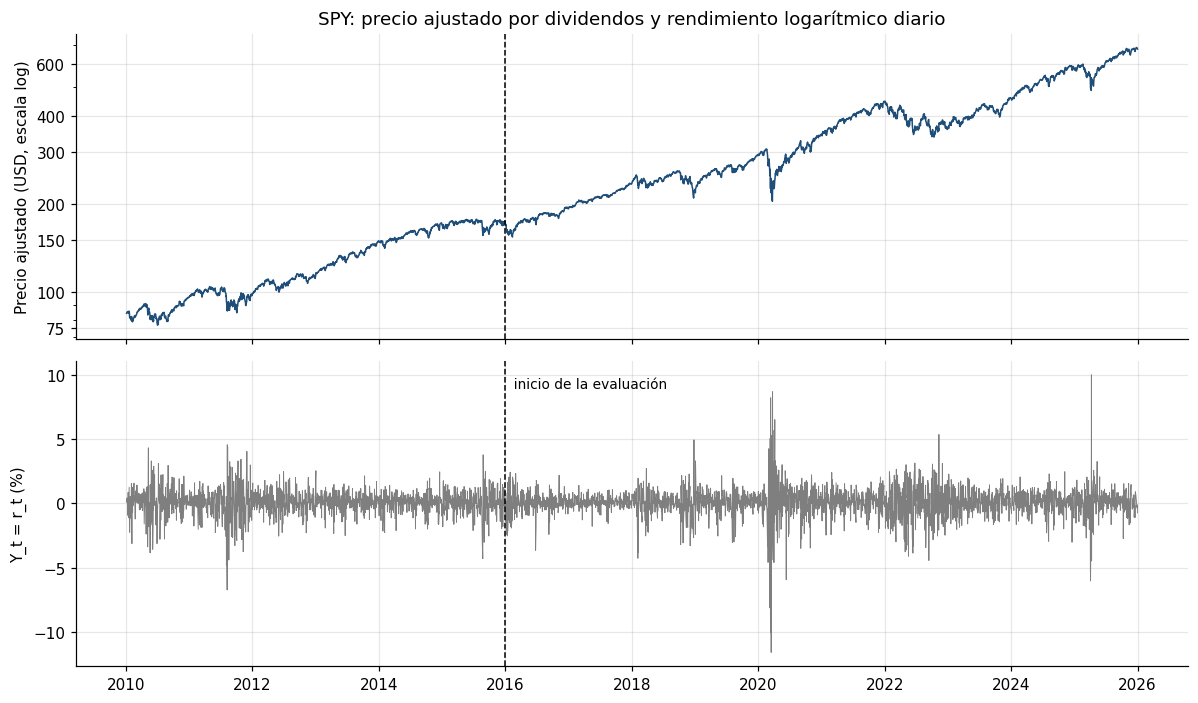

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(price, color=C_HS, lw=1)
ax[0].set_yscale("log")
ax[0].set_yticks([75, 100, 150, 200, 300, 400, 600])
ax[0].yaxis.set_major_formatter(ScalarFormatter())
ax[0].yaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_ylabel("Precio ajustado (USD, escala log)")
ax[0].set_title("SPY: precio ajustado por dividendos y rendimiento logarítmico diario")
ax[1].plot(r, color=C_L, lw=0.6)
ax[1].set_ylabel("Y_t = r_t (%)")
for a in ax:
    a.axvline(pd.Timestamp(OOS_START), color="k", ls="--", lw=1)
ax[1].text(pd.Timestamp(OOS_START), r.max() * 0.9, "  inicio de la evaluación", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura.** El precio, en escala logarítmica, crece de forma sostenida con caídas en agosto de 2011, finales de 2018, febrero y marzo de 2020, 2022 y abril de 2025. Los rendimientos muestran agrupamiento de volatilidad: 2017 es muy tranquilo, marzo de 2020 concentra las mayores oscilaciones en ambas direcciones y 2022 tiene volatilidad alta y persistente. La muestra de evaluación (a la derecha de la línea punteada) contiene todos los episodios extremos posteriores a 2015.

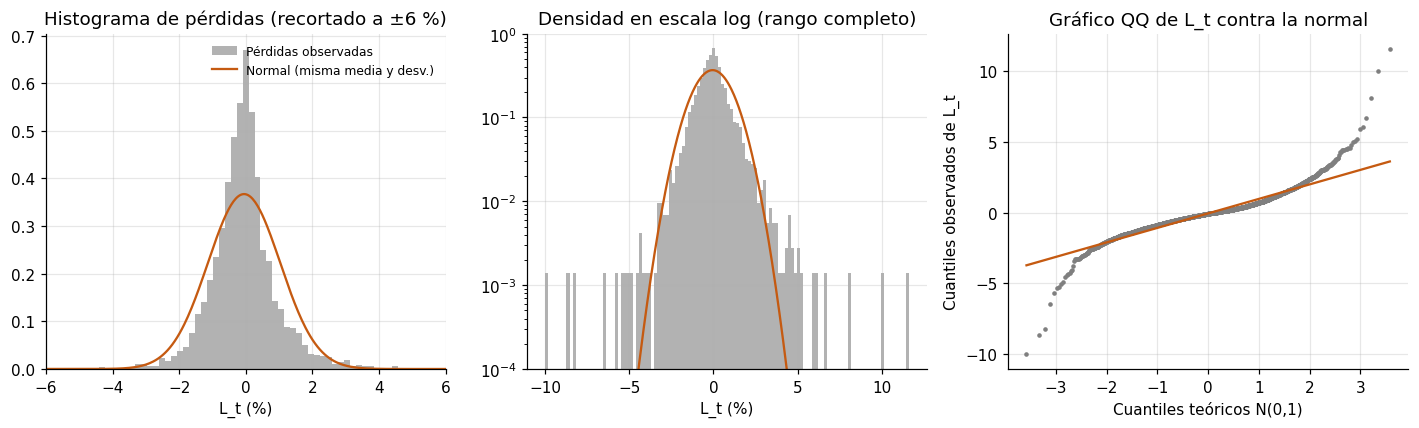

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
grid = np.linspace(L.min(), L.max(), 600)
ax[0].hist(L, bins=120, density=True, color=C_L, alpha=0.6, label="Pérdidas observadas")
ax[0].plot(grid, stats.norm.pdf(grid, mu_L, sd_L), color=C_N, lw=1.5, label="Normal (misma media y desv.)")
ax[0].set_xlim(-6, 6)
ax[0].set_xlabel("L_t (%)")
ax[0].set_title("Histograma de pérdidas (recortado a ±6 %)")
ax[0].legend(fontsize=8)
ax[1].hist(L, bins=120, density=True, color=C_L, alpha=0.6)
ax[1].plot(grid, stats.norm.pdf(grid, mu_L, sd_L), color=C_N, lw=1.5)
ax[1].set_yscale("log")
ax[1].set_ylim(1e-4, 1)
ax[1].set_xlabel("L_t (%)")
ax[1].set_title("Densidad en escala log (rango completo)")
stats.probplot(L, dist="norm", plot=ax[2])
ax[2].get_lines()[0].set(markersize=2, color=C_L)
ax[2].get_lines()[1].set(color=C_N)
ax[2].set_title("Gráfico QQ de L_t contra la normal")
ax[2].set_xlabel("Cuantiles teóricos N(0,1)")
ax[2].set_ylabel("Cuantiles observados de L_t")
plt.tight_layout()
plt.show()

**Lectura.**

- *Histograma.* Los datos tienen un pico central más alto y hombros más delgados que la normal ajustada.
- *Escala logarítmica.* La densidad normal cae como una parábola. La empírica decae mucho más despacio y registra pérdidas superiores al 5 %, a las que la normal asigna probabilidad casi nula.
- *Gráfico QQ.* A partir de unos dos cuantiles teóricos, los puntos se separan de la recta hacia arriba en la cola de pérdidas y hacia abajo en la de ganancias. Las dos colas son más pesadas que las normales y la de pérdidas llega más lejos.

Las tres gráficas cuentan lo mismo que la tabla de colas: una normal con la varianza muestral describe razonablemente el centro de la distribución y falla en la cola, que es justamente la región que miden el VaR y el ES.

## 2. Estimación tradicional del VaR y ES: simulación histórica

### 2.1 Convenciones: nivel $\alpha$, signos y pérdidas

Sea $F$ la distribución de $Y$, el rendimiento de mañana, y $\alpha \in (0,1)$ la probabilidad de cola. Las definiciones son las de Fissler y Ziegel (2016):

$$
\mathrm{VaR}_\alpha(F) = F^{-1}(\alpha) = \inf\{y \in \mathbb{R} : F(y) \ge \alpha\},
\qquad
\mathrm{ES}_\alpha(F) = \frac{1}{\alpha}\int_0^\alpha \mathrm{VaR}_u(F)\,du .
$$

- $\mathrm{VaR}_\alpha(F)$ es el cuantil $\alpha$ (inferior) de los rendimientos: con probabilidad $\alpha$, el resultado de mañana queda por debajo de ese umbral.
- $\mathrm{ES}_\alpha(F)$ es el promedio de los cuantiles de la cola izquierda, es decir, el resultado medio en el peor $\alpha$ de los escenarios. Si $F$ es continua, $\mathrm{ES}_\alpha(F) = E[Y \mid Y \le \mathrm{VaR}_\alpha(F)]$. La definición por la integral también vale cuando hay masas puntuales (sección 2.2) y es la que hace del ES una medida coherente (Acerbi y Tasche, 2002).
- Con $\alpha = 0{,}05$ se espera una excepción cada 20 días; con $\alpha = 0{,}01$, una cada 100 (unas 2,5 al año). Por eso se habla de VaR "al 95 %" y "al 99 %": $1-\alpha$ es el nivel de confianza.
- Para $\alpha$ pequeño, ambos son negativos y siempre $\mathrm{ES}_\alpha \le \mathrm{VaR}_\alpha$, porque el ES promedia cuantiles iguales o menores que el VaR. El VaR no dice cuánto se pierde cuando se supera; el ES sí.

**Notación de pronósticos.** Siguiendo el artículo, un pronóstico del par se escribe $x = (x_1, x_2)$, con $x_1$ para el VaR y $x_2$ para el ES, y el valor verdadero $t = (t_1, t_2) = T(F) = \big(\mathrm{VaR}_\alpha(F), \mathrm{ES}_\alpha(F)\big)$. El dominio natural es $A_0 = \{x : x_1 \ge x_2\}$.

**Pérdidas positivas.** En tablas y gráficas, el VaR y el ES se reportan como pérdidas, con el signo cambiado:

$$
v = -x_1, \qquad e = -x_2, \qquad L = -Y .
$$

Así, un VaR de 1,5 al 95 % significa que, con probabilidad del 95 %, la pérdida logarítmica de mañana no superará el 1,5 % del valor de la posición. En pérdidas, $e \ge v > 0$.

| | Rendimientos (teoría) | Pérdidas (tablas y gráficas) |
|---|---|---|
| Variable | $Y = r$ | $L = -Y$ |
| VaR | $x_1 = F^{-1}(\alpha) < 0$ | $v = -x_1 > 0$ |
| ES | $x_2 = \frac{1}{\alpha}\int_0^\alpha F^{-1}(u)\,du < 0$ | $e = -x_2 > 0$ |
| Excepción | $Y < x_1$ | $L > v$ |
| Dominio | $x_1 \ge x_2$ | $e \ge v$ |

**Unidades.** VaR y ES están en porcentaje del valor de la posición y en escala logarítmica. Para una posición de valor $W$, la pérdida monetaria es $W\,(1-e^{-L/100})$. Como los cuantiles se preservan bajo transformaciones crecientes, el VaR monetario es exactamente $W(1-e^{-v/100})$. Para el ES la conversión es aproximada (desigualdad de Jensen), con un error despreciable a un día.

Este notebook usa $\alpha = 0{,}05$ y $0{,}01$, como pide el ejercicio. Como referencia, el marco regulatorio de Basilea (FRTB) usa el ES con $\alpha = 0{,}025$.

### 2.2 Estimador de simulación histórica

**Intuición.** La simulación histórica toma como $F$ la distribución empírica $F_n$ de las últimas $n$ observaciones. No impone una forma paramétrica, pero sí tres supuestos: que la distribución no cambia dentro de la ventana, que esas $n$ observaciones representan el riesgo de mañana y que la volatilidad actual no aporta información adicional.

**Formulación (en pérdidas).** Con las pérdidas de la ventana ordenadas, $L_{(1)} \le \dots \le L_{(n)}$, y su distribución empírica $F^L_n(\ell) = \tfrac{1}{n}\sum_{i=1}^n \mathbf{1}\{L_i \le \ell\}$:

$$
\hat v_\alpha = L_{(k)}, \qquad k = \lceil n(1-\alpha) \rceil .
$$

Con $n = 500$, $k = 475$ para $\alpha = 0{,}05$ y $k = 495$ para $\alpha = 0{,}01$: el VaR es la 26.ª y la 6.ª mayor pérdida de la ventana.

Para el ES se aplica la definición integral a la distribución empírica. El resultado (Acerbi y Tasche, 2002) es

$$
\hat e_\alpha = \frac{1}{\alpha}\left[\frac{1}{n}\sum_{i=1}^{n} L_i\,\mathbf{1}\{L_i > \hat v_\alpha\} \;+\; \hat v_\alpha\Big(F^L_n(\hat v_\alpha) - (1-\alpha)\Big)\right].
$$

El primer término suma las pérdidas estrictamente mayores que el VaR. El segundo es el **tratamiento explícito de las observaciones en el cuantil**: $F^L_n(\hat v_\alpha) - (1-\alpha)$ es la parte de la masa ubicada exactamente en el VaR que pertenece a la cola de probabilidad $\alpha$. Sin ese término, el ES promediaría una cola de tamaño incorrecto siempre que $n\alpha$ no sea entero o haya empates en el VaR. Una expresión equivalente, útil para verificar, es $\hat e_\alpha = \big[(k - n(1-\alpha))\,L_{(k)} + \sum_{i>k} L_{(i)}\big] / (n\alpha)$.

**Una sutileza de la distribución empírica.** $F_n$ es escalonada, así que el $\alpha$-cuantil no es un punto sino un intervalo: en pérdidas, cualquier valor de $[L_{(k)}, L_{(k+1)})$ deja exactamente una fracción $\alpha$ de observaciones por encima. HS toma el extremo izquierdo, que es el cuantil inferior de $L$. El cuantil inferior de $Y$ que usa el artículo corresponde al extremo derecho. En distribuciones continuas no hay diferencia, y en la sección 4.5 se ve que el ES no depende de qué extremo se elija.

En el código, `np.ceil(n * (1 - alpha) - 1e-9)` evita que un error de redondeo de punto flotante desplace el índice $k$ una posición.

In [11]:
def var_es_hs(losses, alpha):
    x = np.sort(np.asarray(losses, dtype=float))
    n = x.size
    k = int(np.ceil(n * (1 - alpha) - 1e-9))
    var = x[k - 1]
    atom = np.mean(x <= var) - (1 - alpha)
    es = (np.sum(x[x > var]) / n + var * atom) / alpha
    return var, es

**Ejemplo con empates.** Diez pérdidas con cinco valores iguales a 3 y $\alpha = 0{,}30$. La cola de probabilidad 0,30 contiene tres observaciones de masa 0,1 cada una: 10, 5 y una sola de las cinco que valen 3.

In [12]:
toy = np.array([0, 1, 2, 3, 3, 3, 3, 3, 5, 10.0])
v_toy, e_toy = var_es_hs(toy, 0.3)
pd.Series({
    "v (VaR, alpha = 0.30)": v_toy,
    "F_n(v)": np.mean(toy <= v_toy),
    "e (ES con átomo)": e_toy,
    "Promedio de L > v": toy[toy > v_toy].mean(),
    "Promedio de L >= v": toy[toy >= v_toy].mean(),
    "Promedio del 30% superior (3 obs.)": np.sort(toy)[-3:].mean(),
}, name="Ejemplo con empates").to_frame()

,Ejemplo con empates
"v (VaR, alpha = 0.30)",3.0000
F_n(v),0.8000
e (ES con átomo),6.0000
Promedio de L > v,7.5000
Promedio de L >= v,4.2857
Promedio del 30% superior (3 obs.),6.0000


El VaR es 3, pero $F_n(3) = 0{,}8 > 1 - \alpha = 0{,}7$: el valor 3 acumula una masa de 0,5 y solo 0,1 de ella pertenece a la cola. La fórmula con átomo da 6, igual al promedio de las tres observaciones de la cola. Promediar las pérdidas mayores que el VaR da 7,5, porque usa una cola de 0,2 y sobreestima el ES. Promediar las mayores o iguales da 4,29, porque usa una cola de 0,7 y lo subestima.

**Verificación independiente** sobre la primera ventana de 500 días (2014-01-08 a 2015-12-31):

- el VaR se compara con `np.quantile(..., method="inverted_cdf")`, que implementa por separado la misma definición de cuantil inferior;
- el ES se compara con la fórmula de estadísticos de orden y con una integral numérica de la función cuantil empírica sobre $(1-\alpha, 1)$.

También se incluye $\alpha = 0{,}025$, donde $n(1-\alpha) = 487{,}5$ no es entero y el término del átomo sí se activa.

In [13]:
def es_order_stats(losses, alpha):
    x = np.sort(np.asarray(losses, dtype=float))
    n = x.size
    k = int(np.ceil(n * (1 - alpha) - 1e-9))
    return ((k - n * (1 - alpha)) * x[k - 1] + x[k:].sum()) / (n * alpha)


def es_quantile_integral(losses, alpha, m=200_000):
    u = (1 - alpha) + (np.arange(m) + 0.5) * alpha / m
    return np.quantile(np.asarray(losses, dtype=float), u, method="inverted_cdf").mean()


w0 = L.iloc[np.flatnonzero(is_oos)[0] - WINDOW: np.flatnonzero(is_oos)[0]]
rows = {}
for a in (0.05, 0.025, 0.01):
    v, e = var_es_hs(w0, a)
    rows[f"{nivel(a)} (alpha = {a})"] = {
        "n(1-alpha)": WINDOW * (1 - a),
        "v": v, "v np.quantile(inverted_cdf)": np.quantile(w0, 1 - a, method="inverted_cdf"),
        "v np.quantile(linear)": np.quantile(w0, 1 - a),
        "e": e, "e estadísticos de orden": es_order_stats(w0, a),
        "e integral numérica": es_quantile_integral(w0, a),
        "Obs. en la cola (L > v)": int(np.sum(w0 > v)),
    }
pd.DataFrame(rows).T

,n(1-alpha),v,v np.quantile(inverted_cdf),v np.quantile(linear),e,e estadísticos de orden,e integral numérica,Obs. en la cola (L > v)
95% (alpha = 0.05),475.0000,1.4165,1.4165,1.4195,2.0355,2.0355,2.0355,25.0000
97.5% (alpha = 0.025),487.5000,1.8225,1.8225,1.8106,2.4466,2.4466,2.4466,12.0000
99% (alpha = 0.01),495.0000,2.1567,2.1567,2.1579,3.0413,3.0413,3.0413,5.0000


**Lectura.** Los tres cálculos del ES coinciden, y el VaR coincide con `inverted_cdf` en todos los niveles. El método por defecto de NumPy (`linear`) interpola entre estadísticos de orden y da un VaR algo distinto (1,4195 frente a 1,4165 al 95 %). La diferencia es pequeña, pero cambia qué días cuentan como excepción, así que la convención debe fijarse y documentarse.

Con $\alpha = 0{,}025$ hay 12 observaciones estrictamente por encima del VaR y el VaR entra con peso $488 - 487{,}5 = 0{,}5$, de modo que la cola suma $12{,}5/500 = 2{,}5\,\%$. Con $\alpha = 0{,}05$ y $0{,}01$, $n\alpha$ es entero; si no hay empates, el término del átomo vale cero y el ES es el promedio simple de las 25 y de las 5 mayores pérdidas. Esto también muestra la principal debilidad de HS al 99 %: **su ES descansa en cinco observaciones**.

### 2.3 Pronósticos diarios con ventana móvil

Para cada día $t$ de la muestra de evaluación se toma la ventana $\{L_{t-500}, \dots, L_{t-1}\}$ y se calculan $\hat v_{\alpha,t}$ y $\hat e_{\alpha,t}$, que son pronósticos para el día $t$ a un día de horizonte. La ventana nunca incluye el día pronosticado.

In [14]:
Lv = L.to_numpy()
pos = np.flatnonzero(is_oos)
assert pos[0] >= WINDOW
dates = L.index[pos]
L_eval = L.iloc[pos]

hs = {}
for a in LEVELS:
    out = np.array([var_es_hs(Lv[t - WINDOW:t], a) for t in pos])
    hs[a] = pd.DataFrame(out, index=dates, columns=["VaR", "ES"])

pd.Series({
    "Primer día pronosticado": dates[0].date(),
    "Ventana usada: primera fecha": L.index[pos[0] - WINDOW].date(),
    "Ventana usada: última fecha": L.index[pos[0] - 1].date(),
    "Último día pronosticado": dates[-1].date(),
    "Número de pronósticos": len(dates),
}, name="Esquema de ventana móvil").to_frame()

,Esquema de ventana móvil
Primer día pronosticado,2016-01-04
Ventana usada: primera fecha,2014-01-08
Ventana usada: última fecha,2015-12-31
Último día pronosticado,2025-12-31
Número de pronósticos,2514


Se generan 2.514 pronósticos por nivel. El del 4 de enero de 2016 usa información hasta el 31 de diciembre de 2015, lo que confirma que no hay información futura en la ventana.

**Verificación sobre todas las ventanas.** Se recalcula el VaR de las 2.514 ventanas con `np.quantile` y el ES con estadísticos de orden; además se cuentan los empates en el VaR y se comprueba que $e \ge v$.

In [15]:
from numpy.lib.stride_tricks import sliding_window_view

win = sliding_window_view(Lv[pos[0] - WINDOW: pos[-1]], WINDOW)
assert win.shape[0] == len(pos)
chk = {}
for a in LEVELS:
    q_np = np.quantile(win, 1 - a, axis=1, method="inverted_cdf")
    es_os = np.array([es_order_stats(w, a) for w in win])
    ties = np.array([np.sum(w == v) for w, v in zip(win, hs[a]["VaR"])])
    chk[nivel(a)] = {
        "máx |v - np.quantile|": np.max(np.abs(hs[a]["VaR"].to_numpy() - q_np)),
        "máx |e - e orden|": np.max(np.abs(hs[a]["ES"].to_numpy() - es_os)),
        "ventanas con empates en el VaR": int(np.sum(ties > 1)),
        "e >= v en todas": bool(np.all(hs[a]["ES"] >= hs[a]["VaR"])),
    }
pd.DataFrame(chk).T

,máx |v - np.quantile|,máx |e - e orden|,ventanas con empates en el VaR,e >= v en todas
95%,0.0000,0.0000,0,True
99%,0.0000,0.0000,0,True


Las diferencias son cero, no hay empates en el VaR en ninguna ventana y el ES siempre es mayor o igual que el VaR (en pérdidas).

In [16]:
def resumen_pronosticos(fc):
    out = {}
    for a, df in fc.items():
        for m in ("VaR", "ES"):
            s = df[m]
            out[(nivel(a), m)] = {"Media": s.mean(), "Desv. est.": s.std(), "Mínimo": s.min(),
                                  "Máximo": s.max(), "Último": s.iloc[-1]}
    return pd.DataFrame(out).T


resumen_pronosticos(hs)

Media  Desv. est.  Mínimo  Máximo  Último
95% VaR 1.7117      0.4534  0.8288  2.5901  1.5385
    ES  2.6868      0.8511  1.3052  4.3294  2.4139
99% VaR 3.1553      1.0022  1.4480  4.9977  2.7400
    ES  4.4145      1.9199  2.2497  8.1821  4.3097

**Hallazgo empírico.** En la muestra de evaluación, el VaR HS al 95 % promedia 1,71 % (entre 0,83 % y 2,59 %) y el ES 2,69 %. Al 99 %, el VaR promedia 3,16 % y el ES 4,41 %, con un máximo de 8,18 %. La razón ES/VaR al 95 % es de alrededor de 1,57. Para una normal centrada sería 1,25 ($2{,}063/1{,}645$): el ES empírico se separa del VaR más de lo que permitiría una cola normal.

La tabla siguiente muestra un pronóstico por año junto con la pérdida realizada ese día.

In [17]:
pd.concat({nivel(a): hs[a] for a in LEVELS}, axis=1).assign(L=L_eval).iloc[::250]

95%           99%              L
              VaR     ES    VaR     ES        
Date                                          
2016-01-04 1.4165 2.0355 2.1567 3.0413  1.4078
2016-12-29 1.4101 2.1427 2.5257 3.3175  0.0223
2017-12-27 1.0038 1.6589 1.9234 2.6407 -0.0486
2018-12-26 1.4648 2.3056 2.6778 3.5367 -4.9290
2019-12-23 1.7744 2.5310 3.0534 3.5367 -0.1527
2020-12-18 2.4152 4.2866 4.9977 8.1821  0.4001
2021-12-16 2.2556 4.2251 4.9977 8.1821  0.8858
2022-12-14 2.0644 2.8708 3.4436 3.9631  0.6414
2023-12-13 1.9826 2.8405 3.4436 3.9631 -1.3696
2024-12-11 1.3899 1.7384 1.9798 2.3661 -0.7701
2025-12-11 1.5385 2.4139 2.7400 4.3097 -0.2324

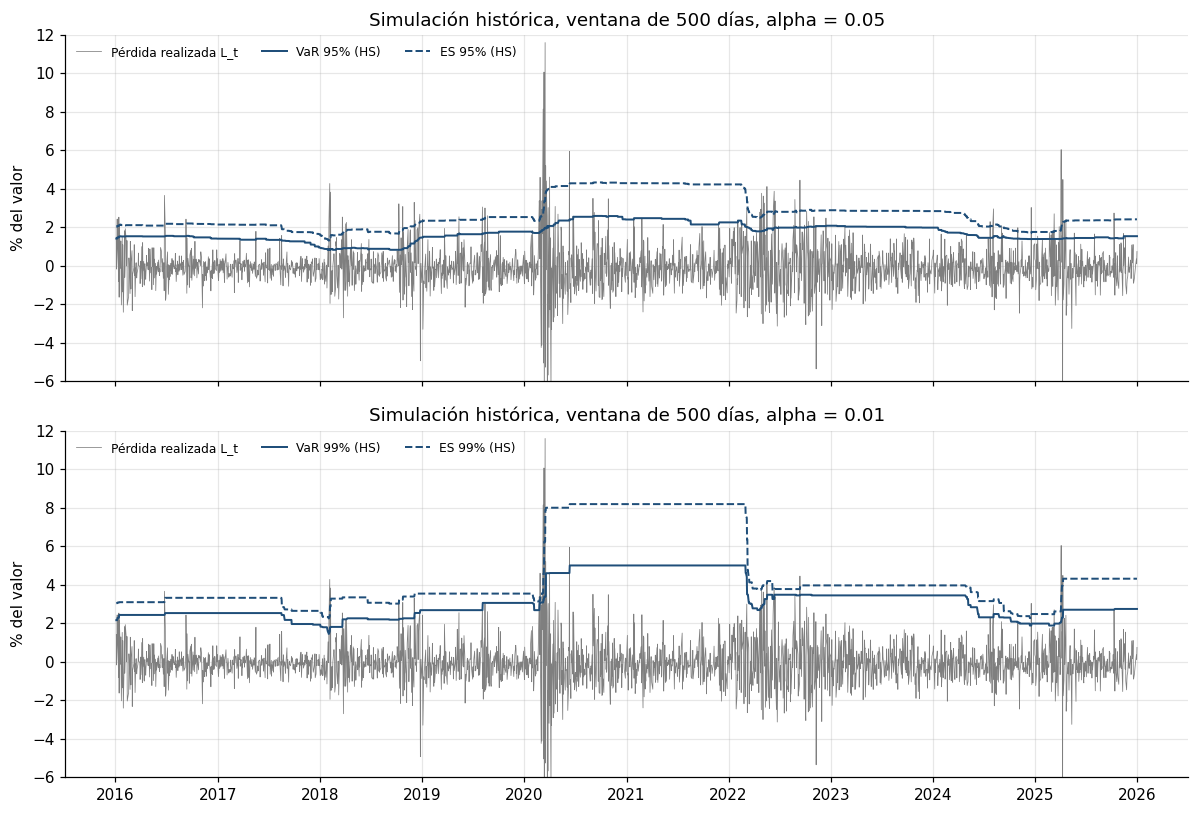

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, a in zip(axes, LEVELS):
    ax.plot(L_eval, color=C_L, lw=0.5, label="Pérdida realizada L_t")
    ax.plot(hs[a]["VaR"], color=C_HS, lw=1.3, label=f"VaR {nivel(a)} (HS)")
    ax.plot(hs[a]["ES"], color=C_HS, lw=1.3, ls="--", label=f"ES {nivel(a)} (HS)")
    ax.set_ylabel("% del valor")
    ax.set_title(f"Simulación histórica, ventana de {WINDOW} días, alpha = {a}")
    ax.legend(loc="upper left", fontsize=8, ncol=3)
    ax.set_ylim(-6, 12)
plt.tight_layout()
plt.show()

**Lectura.** El eje vertical se recorta en −6 % para ver mejor la cola de pérdidas; las ganancias extremas quedan fuera del gráfico.

- Las series son escalonadas: el VaR y el ES de HS solo cambian cuando una pérdida grande entra o sale de la ventana.
- La reacción a marzo de 2020 llega tarde: el VaR sube después de varias pérdidas grandes, no antes.
- Al 99 %, el ES salta a 8,18 % en marzo de 2020 y se mantiene ahí unos dos años. Cae de golpe en marzo de 2022, cuando esas pérdidas salen de la ventana de 500 días. Esa caída no refleja una reducción del riesgo; de hecho, coincide con el aumento de la volatilidad de 2022. Es el "efecto fantasma" propio de las ventanas fijas con pesos iguales.

## 3. Backtesting del VaR: calibración absoluta

### 3.1 Excepciones y la hipótesis de cobertura condicional

La serie de excepciones es

$$
I_t = \mathbf{1}\{Y_t < x_{1,t}\} = \mathbf{1}\{L_t > \hat v_{\alpha,t}\}, \qquad t = 1, \dots, T .
$$

Si el VaR es correcto condicionalmente a la información disponible, $P(I_t = 1 \mid \mathcal{F}_{t-1}) = \alpha$, y entonces las $I_t$ son **independientes e idénticamente distribuidas Bernoulli$(\alpha)$** (Christoffersen, 1998). Esta hipótesis tiene dos partes que se contrastan por separado:

1. **Cobertura incondicional:** la tasa de excepciones es $\alpha$.
2. **Independencia:** una excepción hoy no cambia la probabilidad de excepción mañana.

$I_t - \alpha$ es la primera componente de la función de identificación del par (VaR, ES) que aparece en la sección 4.4, $V_1(x, y) = \mathbf{1}\{y \le x_1\} - \alpha$. Estas pruebas contrastan que esa función tenga media cero (incondicional o condicional al pasado): son pruebas de **calibración absoluta sobre un solo modelo**, basadas en identificabilidad. No ordenan modelos.

Un modelo puede acertar la tasa promedio y concentrar las excepciones en los peores momentos, que es cuando más importa.

### 3.2 Prueba de cobertura incondicional de Kupiec (1995)

Sean $x = \sum_t I_t$ el número de excepciones y $\hat\pi = x/T$ la tasa observada. La razón de verosimilitudes compara la verosimilitud binomial con tasa $\alpha$ frente a la evaluada en $\hat\pi$:

$$
LR_{uc} = -2\ln\!\left[\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}}\right] \;\overset{H_0}{\sim}\; \chi^2_1 .
$$

Si $\hat\pi$ se aleja de $\alpha$ en cualquier dirección, $LR_{uc}$ crece. Demasiadas excepciones indican que el modelo subestima el riesgo; muy pocas, que lo sobreestima. Cuando $x = 0$ aparecen términos $0 \cdot \ln 0$, que se toman como cero (`xlogy`).

### 3.3 Prueba de Christoffersen (1998)

Se modela $I_t$ como una cadena de Markov de primer orden. Con $n_{ij}$ igual al número de días en que $I_{t-1} = i$ e $I_t = j$:

$$
\hat\pi_{01} = \frac{n_{01}}{n_{00}+n_{01}}, \qquad
\hat\pi_{11} = \frac{n_{11}}{n_{10}+n_{11}}, \qquad
\hat\pi = \frac{n_{01}+n_{11}}{n_{00}+n_{01}+n_{10}+n_{11}} .
$$

$\hat\pi_{01}$ es la probabilidad estimada de excepción después de un día sin excepción, y $\hat\pi_{11}$ después de un día con excepción. Bajo independencia, ambas son iguales.

$$
LR_{ind} = -2\ln\!\left[\frac{(1-\hat\pi)^{n_{00}+n_{10}}\,\hat\pi^{\,n_{01}+n_{11}}}{(1-\hat\pi_{01})^{n_{00}}\,\hat\pi_{01}^{\,n_{01}}\,(1-\hat\pi_{11})^{n_{10}}\,\hat\pi_{11}^{\,n_{11}}}\right] \;\overset{H_0}{\sim}\; \chi^2_1,
$$

$$
LR_{cc} = -2\ln\!\left[\frac{(1-\alpha)^{n_{00}+n_{10}}\,\alpha^{\,n_{01}+n_{11}}}{(1-\hat\pi_{01})^{n_{00}}\,\hat\pi_{01}^{\,n_{01}}\,(1-\hat\pi_{11})^{n_{10}}\,\hat\pi_{11}^{\,n_{11}}}\right] \;\overset{H_0}{\sim}\; \chi^2_2 .
$$

$LR_{cc}$ contrasta conjuntamente tasa correcta e independencia. Calculada sobre las mismas $T-1$ transiciones, cumple $LR_{cc} = LR_{uc} + LR_{ind}$; con $LR_{uc}$ sobre las $T$ observaciones, la igualdad es aproximada.

In [19]:
def kupiec_test(hits, alpha):
    h = np.asarray(hits, dtype=int)
    n, x = h.size, int(h.sum())
    pi_hat = x / n
    ll0 = xlogy(n - x, 1 - alpha) + xlogy(x, alpha)
    ll1 = xlogy(n - x, 1 - pi_hat) + xlogy(x, pi_hat)
    lr = -2 * (ll0 - ll1)
    return {"n": n, "excepciones": x, "esperadas": n * alpha, "tasa observada": pi_hat,
            "alpha": alpha, "LR_uc": lr, "p_uc": stats.chi2.sf(lr, 1)}


def transition_counts(hits):
    h = np.asarray(hits, dtype=int)
    prev, curr = h[:-1], h[1:]
    return (int(np.sum((prev == 0) & (curr == 0))), int(np.sum((prev == 0) & (curr == 1))),
            int(np.sum((prev == 1) & (curr == 0))), int(np.sum((prev == 1) & (curr == 1))))


def christoffersen_test(hits, alpha):
    n00, n01, n10, n11 = transition_counts(hits)
    pi01 = n01 / (n00 + n01) if n00 + n01 > 0 else 0.0
    pi11 = n11 / (n10 + n11) if n10 + n11 > 0 else 0.0
    pi1 = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_markov = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    ll_iid = xlogy(n00 + n10, 1 - pi1) + xlogy(n01 + n11, pi1)
    ll_null = xlogy(n00 + n10, 1 - alpha) + xlogy(n01 + n11, alpha)
    lr_ind = -2 * (ll_iid - ll_markov)
    lr_cc = -2 * (ll_null - ll_markov)
    return {"n00": n00, "n01": n01, "n10": n10, "n11": n11, "pi01": pi01, "pi11": pi11,
            "LR_ind": lr_ind, "p_ind": stats.chi2.sf(lr_ind, 1),
            "LR_cc": lr_cc, "p_cc": stats.chi2.sf(lr_cc, 2)}

**Verificación a mano.** Secuencia de 20 días con 4 excepciones y $\alpha = 0{,}10$. Los conteos se obtienen inspeccionando la secuencia y los estadísticos se calculan directamente con las fórmulas anteriores, sin usar las funciones.

In [20]:
toy_hits = np.array([0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0])
k_toy, c_toy = kupiec_test(toy_hits, 0.1), christoffersen_test(toy_hits, 0.1)
n, x, a_toy = 20, 4, 0.1
lr_uc_hand = -2 * np.log(((1 - a_toy) ** (n - x) * a_toy**x) / ((1 - x / n) ** (n - x) * (x / n) ** x))
n00, n01, n10, n11 = 12, 3, 3, 1
pi01, pi11, pi1 = 3 / 15, 1 / 4, 4 / 19
lr_ind_hand = -2 * np.log(((1 - pi1) ** 15 * pi1**4) /
                          ((1 - pi01) ** n00 * pi01**n01 * (1 - pi11) ** n10 * pi11**n11))
pd.DataFrame({
    "Función": [k_toy["LR_uc"], c_toy["LR_ind"], (c_toy["n00"], c_toy["n01"], c_toy["n10"], c_toy["n11"])],
    "A mano": [lr_uc_hand, lr_ind_hand, (n00, n01, n10, n11)],
}, index=["LR_uc", "LR_ind", "conteos (n00, n01, n10, n11)"])

,Función,A mano
LR_uc,1.7761,1.7761
LR_ind,0.0461,0.0461
"conteos (n00, n01, n10, n11)","(12, 3, 3, 1)","(12, 3, 3, 1)"


Las funciones reproducen el cálculo manual.

### 3.4 Validez de la aproximación $\chi^2$

Las distribuciones $\chi^2$ son asintóticas. Con $T = 2.514$ y $\alpha = 0{,}01$ se esperan unas 25 excepciones y muy pocas transiciones desde el estado 1, así que la aproximación puede fallar. Para medirlo se simulan 20.000 secuencias Bernoulli$(\alpha)$ i.i.d. de longitud $T$, es decir, bajo $H_0$ exacta, y se calcula con qué frecuencia cada prueba rechaza al 5 % usando los valores críticos $\chi^2$ (tamaño empírico).

Las mismas simulaciones dan **p-valores de Monte Carlo**, que no dependen de la aproximación asintótica:

$$
p_{MC} = \frac{1 + \#\{LR^{(s)} \ge LR_{obs}\}}{N + 1}, \qquad N = 20.000 .
$$

In [21]:
def lr_from_counts(x, n, n00, n01, n10, n11, alpha):
    pi_hat = x / n
    lr_uc = -2 * (xlogy(n - x, 1 - alpha) + xlogy(x, alpha) - xlogy(n - x, 1 - pi_hat) - xlogy(x, pi_hat))
    with np.errstate(invalid="ignore", divide="ignore"):
        pi01 = np.where(n00 + n01 > 0, n01 / np.maximum(n00 + n01, 1), 0.0)
        pi11 = np.where(n10 + n11 > 0, n11 / np.maximum(n10 + n11, 1), 0.0)
    pi1 = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_markov = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    ll_iid = xlogy(n00 + n10, 1 - pi1) + xlogy(n01 + n11, pi1)
    ll_null = xlogy(n00 + n10, 1 - alpha) + xlogy(n01 + n11, alpha)
    return lr_uc, -2 * (ll_iid - ll_markov), -2 * (ll_null - ll_markov)


def simulate_null(T, alpha, nsim=20_000, seed=0):
    g = np.random.default_rng(seed)
    H = g.random((nsim, T)) < alpha
    prev, curr = H[:, :-1], H[:, 1:]
    n11 = np.sum(prev & curr, axis=1)
    n10 = np.sum(prev & ~curr, axis=1)
    n01 = np.sum(~prev & curr, axis=1)
    n00 = (T - 1) - n11 - n10 - n01
    return np.column_stack(lr_from_counts(H.sum(axis=1), T, n00, n01, n10, n11, alpha))


null_dist = {a: simulate_null(len(pos), a, seed=int(round(100 * (1 - a)))) for a in LEVELS}
size = {}
for a in LEVELS:
    lr = null_dist[a]
    size[nivel(a)] = {
        "Tamaño empírico Kupiec (5%)": np.mean(stats.chi2.sf(lr[:, 0], 1) < 0.05),
        "Tamaño empírico Indep. (5%)": np.mean(stats.chi2.sf(lr[:, 1], 1) < 0.05),
        "Tamaño empírico Cond. (5%)": np.mean(stats.chi2.sf(lr[:, 2], 2) < 0.05),
    }
pd.DataFrame(size)

,95%,99%
Tamaño empírico Kupiec (5%),0.0498,0.0571
Tamaño empírico Indep. (5%),0.0528,0.0187
Tamaño empírico Cond. (5%),0.0553,0.0341


**Lectura.** Con $\alpha = 0{,}05$, las tres pruebas rechazan cerca del 5 % nominal. Con $\alpha = 0{,}01$, Kupiec rechaza algo de más (5,7 %) y la prueba de independencia rechaza bastante de menos (1,9 %): con pocas excepciones, rara vez hay dos seguidas y el estadístico tiene poca variación. Una prueba de independencia que rechace con $\alpha = 0{,}01$ lo hace a pesar de ser conservadora. Por eso, junto a los p-valores asintóticos, se reportan los de Monte Carlo.

### 3.5 Resultados del backtesting para simulación histórica

La función `backtest_table` reúne Kupiec, la prueba binomial exacta (una verificación independiente de Kupiec que no usa aproximaciones), Christoffersen y los p-valores de Monte Carlo.

In [22]:
def backtest_table(fc, model):
    rows = {}
    for a, df in fc.items():
        hits = (L_eval > df["VaR"]).astype(int)
        k = kupiec_test(hits, a)
        c = christoffersen_test(hits, a)
        lr_obs = lr_from_counts(k["excepciones"], k["n"], c["n00"], c["n01"], c["n10"], c["n11"], a)
        mc = [(1 + np.sum(null_dist[a][:, j] >= lr_obs[j] - 1e-12)) / (len(null_dist[a]) + 1) for j in range(3)]
        rows[(model, nivel(a))] = {
            **k, "p binomial exacta": stats.binomtest(k["excepciones"], k["n"], a).pvalue,
            "p_uc MC": mc[0], **c, "p_ind MC": mc[1], "p_cc MC": mc[2],
        }
    return pd.DataFrame(rows).T


COLS_UC = ["excepciones", "esperadas", "tasa observada", "alpha", "LR_uc", "p_uc", "p binomial exacta", "p_uc MC"]
COLS_CC = ["n01", "n11", "pi01", "pi11", "LR_ind", "p_ind", "p_ind MC", "LR_cc", "p_cc", "p_cc MC"]
bt_hs = backtest_table(hs, "HS")
bt_hs[COLS_UC]

excepciones  esperadas  tasa observada  alpha  LR_uc   p_uc  p binomial exacta  p_uc MC
HS 95%     125.0000   125.7000          0.0497 0.0500 0.0041 0.9489             1.0000   0.9630
   99%      41.0000    25.1400          0.0163 0.0100 8.4885 0.0036             0.0034   0.0051

In [23]:
bt_hs[COLS_CC]

n01     n11   pi01   pi11  LR_ind  p_ind  p_ind MC   LR_cc   p_cc  p_cc MC
HS 95% 106.0000 19.0000 0.0444 0.1520 19.8103 0.0000    0.0001 19.8138 0.0000   0.0001
   99%  36.0000  5.0000 0.0146 0.1220 12.4262 0.0004    0.0001 20.9275 0.0000   0.0000

**Hallazgo empírico (cobertura incondicional).**

- Con $\alpha = 0{,}05$ hubo 125 excepciones frente a 125,7 esperadas (tasa de 4,97 %). $LR_{uc} = 0{,}004$ con p-valor de 0,95; la prueba exacta (1,00) y la de Monte Carlo (0,96) llevan a la misma conclusión. No hay evidencia contra la cobertura incondicional.
- Con $\alpha = 0{,}01$ hubo 41 excepciones frente a 25,1 esperadas (1,63 %). $LR_{uc} = 8{,}49$ con p-valor de 0,004 (exacta: 0,003; Monte Carlo: 0,005). Se rechaza: HS subestima el VaR del 99 %. La causa es la de la sección 2.2: el cuantil se estima con las 5 pérdidas mayores de la ventana, que tras periodos tranquilos no contiene escenarios suficientemente extremos.

**Hallazgo empírico (independencia).**

- Con $\alpha = 0{,}05$, la probabilidad de excepción tras un día sin excepción es $\hat\pi_{01} = 4{,}4\,\%$ y tras un día con excepción es $\hat\pi_{11} = 15{,}2\,\%$, unas 3,4 veces mayor. $LR_{ind} = 19{,}8$ y el p-valor es menor que 0,001.
- Con $\alpha = 0{,}01$, $\hat\pi_{01} = 1{,}5\,\%$ y $\hat\pi_{11} = 12{,}2\,\%$. $LR_{ind} = 12{,}4$ y el p-valor es 0,0004, a pesar de que esta prueba es conservadora en ese nivel.
- La prueba conjunta $LR_{cc}$ rechaza en ambos niveles.

Al 95 %, HS acierta el número total de excepciones, pero no su ubicación en el tiempo: no está condicionalmente calibrado. La tabla por año lo muestra.

In [24]:
def hits_by_year(fc, model):
    return pd.DataFrame({(model, nivel(a)): (L_eval > df["VaR"]).groupby(L_eval.index.year).sum()
                         for a, df in fc.items()})


days_per_year = L_eval.groupby(L_eval.index.year).size()
hits_by_year(hs, "HS").assign(**{f"Esperadas {nivel(a)}": days_per_year * a for a in LEVELS})

HS     Esperadas 95% Esperadas 99%
     95% 99%                            
Date                                    
2016   8   3       12.6000        2.5200
2017   3   0       12.5500        2.5100
2018  33  10       12.5500        2.5100
2019   8   1       12.6000        2.5200
2020  23  11       12.6500        2.5300
2021   2   0       12.6000        2.5200
2022  23   8       12.5500        2.5100
2023   0   0       12.5000        2.5000
2024   7   2       12.6000        2.5200
2025  18   6       12.5000        2.5000

Con $\alpha = 0{,}05$ se esperan unas 12,6 excepciones por año. Hubo 33 en 2018, 23 en 2020, 23 en 2022 y 18 en 2025, frente a 3 en 2017, 2 en 2021 y ninguna en 2023. El total de diez años parece correcto porque los excesos de los años turbulentos se compensan con los déficits de los años tranquilos. Es el patrón que predice el agrupamiento de volatilidad de la sección 1.3: una ventana de 500 días con pesos iguales no distingue un mes tranquilo de uno turbulento.

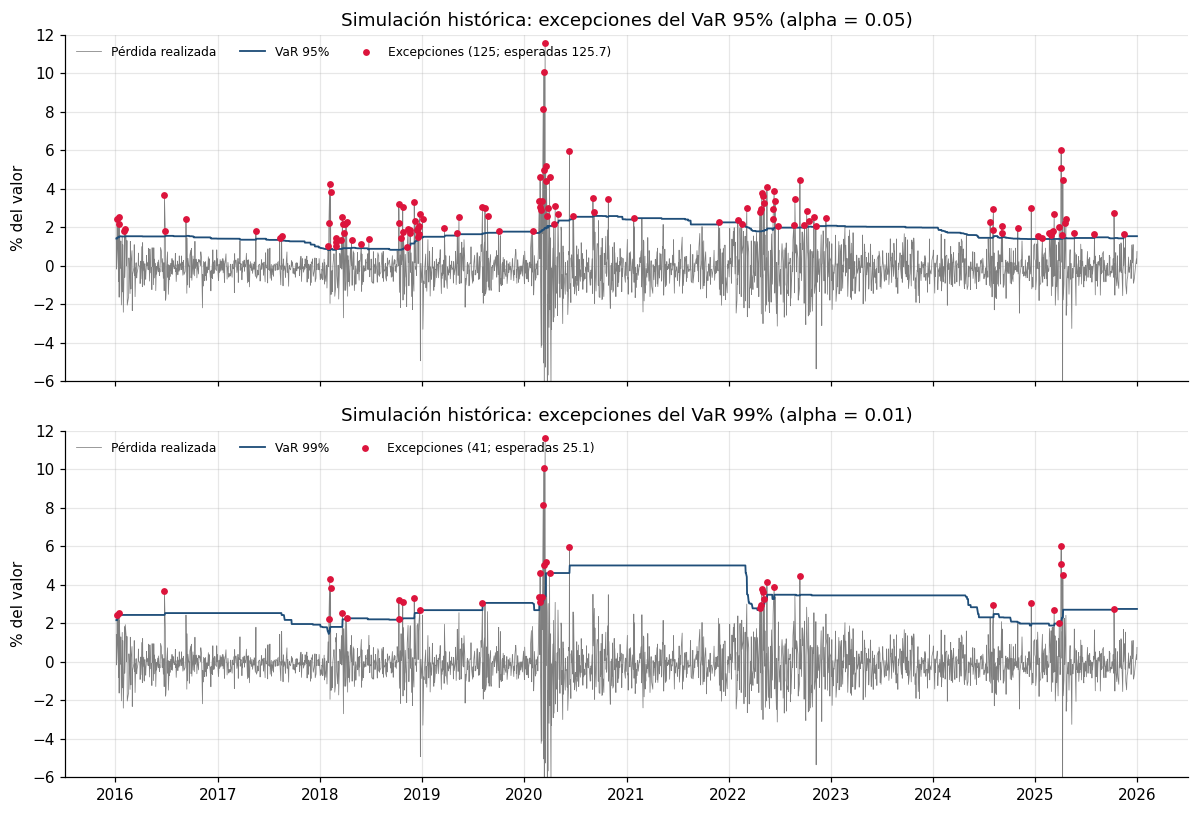

In [25]:
def plot_violations(fc, model, color):
    fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
    for ax, a in zip(axes, LEVELS):
        df = fc[a]
        hit = L_eval > df["VaR"]
        ax.plot(L_eval, color=C_L, lw=0.5, label="Pérdida realizada")
        ax.plot(df["VaR"], color=color, lw=1.2, label=f"VaR {nivel(a)}")
        ax.scatter(L_eval.index[hit], L_eval[hit], color="crimson", s=12, zorder=3,
                   label=f"Excepciones ({hit.sum()}; esperadas {len(hit) * a:.1f})")
        ax.set_ylim(-6, 12)
        ax.set_ylabel("% del valor")
        ax.set_title(f"{model}: excepciones del VaR {nivel(a)} (alpha = {a})")
        ax.legend(loc="upper left", fontsize=8, ncol=3)
    plt.tight_layout()
    plt.show()


plot_violations(hs, "Simulación histórica", C_HS)

**Lectura.** Las excepciones (puntos rojos) se agrupan en febrero y en el cuarto trimestre de 2018, en febrero y marzo de 2020, a lo largo de 2022 y en abril de 2025. En cada episodio, el VaR sube solo después de las primeras excepciones. Entre episodios hay periodos largos sin ninguna, como 2017, 2021 y 2023.

## 4. Evaluación conjunta del VaR y ES

Las pruebas de la sección 3 tienen dos limitaciones. Solo evalúan el VaR, sin decir nada sobre el ES. Además, son pruebas de hipótesis sobre un modelo: dicen si es compatible con su promesa, pero no cuál de dos modelos es mejor cuando ambos pasan o ambos fallan.

Ordenar modelos requiere una función de scoring que asigne una penalización a cada pronóstico y a cada realización, y luego promediar. Ese ranking solo tiene sentido si la función es consistente para lo que se pronostica. Esta sección sigue el orden lógico del argumento: el marco formal (4.1), la imposibilidad del ES aislado (4.2), la elicitabilidad conjunta del par (4.3), el principio de Osband que explica la forma de la familia (4.4), la elección concreta del score y su relación con HS (4.5), el segundo modelo (4.6) y el ranking empírico (4.7).

### 4.1 Marco formal de elicitabilidad

Sea $T(F)$ un funcional definido sobre una familia de distribuciones $\mathcal{F}$, con valores en $\mathbb{R}^k$. Una función de scoring $S(x, y)$ penaliza el reporte $x$ cuando se realiza $y$ (menor es mejor), y su **score esperado** es

$$
\bar S(x, F) = E_F\big[S(x, Y)\big].
$$

$S$ es **$\mathcal{F}$-consistente** para $T$ si $\bar S(t, F) \le \bar S(x, F)$ para todo $x$ y toda $F \in \mathcal{F}$, con $t = T(F)$. Es **estrictamente $\mathcal{F}$-consistente** si además $t$ es el único minimizador global. $T$ es **$k$-elicitable** si existe una $S$ estrictamente consistente para él (Gneiting, 2011; Fissler y Ziegel, 2016).

**Por qué importa.** Con una $S$ estrictamente consistente, a quien pronostica le conviene reportar el verdadero $T(F)$: cualquier otro reporte empeora su score esperado. El promedio de scores realizados estima el score esperado, de modo que ordenar modelos por su promedio es coherente con el objetivo de pronosticar $T$. Con una función no consistente, un pronóstico distorsionado puede obtener mejor score promedio que uno honesto.

**Resultado teórico: la media.** Las funciones consistentes para la media son las distancias de Bregman, $S(x, y) = \phi(y) - \phi(x) - \phi'(x)(y - x)$ con $\phi$ estrictamente convexa; con $\phi(x) = x^2$ se obtiene el error cuadrático. La distancia de Bregman vuelve a aparecer en la componente del ES del score conjunto (sección 4.3).

**Resultado teórico: el VaR es 1-elicitable.** Para el cuantil de nivel $\alpha$, la *pinball loss* o función de verificación generalizada (Gneiting, 2011) es

$$
S(x, y) = \big(\mathbf{1}\{y \le x\} - \alpha\big)\,g(x) - \mathbf{1}\{y \le x\}\,g(y),
$$

con $g$ estrictamente creciente; $g(x) = x$ da la pinball loss usual, $(\mathbf{1}\{y \le x\} - \alpha)(x - y)$, salvo un término que depende solo de $y$. La prueba toma la diferencia del score esperado entre un reporte $x$ y el valor verdadero $t = \mathrm{VaR}_\alpha(F)$:

$$
\bar S(x, F) - \bar S(t, F) = \int_t^x \big(F(y) - \alpha\big)\,g'(y)\,dy .
$$

Como $g' > 0$ y $F(y) - \alpha$ tiene el mismo signo que $y - t$, la integral es estrictamente positiva para todo $x \ne t$ cuando el cuantil es único. La familia de referencia son las distribuciones con primer momento finito.

### 4.2 Imposibilidad del ES aislado

**Qué se quiere demostrar.** Que no existe ninguna función de scoring escalar $S: \mathbb{R} \times \mathbb{R} \to \mathbb{R}$ que vuelva al $\mathrm{ES}_\alpha$ 1-elicitable de forma aislada.

**Idea decisiva: conjuntos de nivel convexos** (Osband, 1985; Gneiting, 2011). Si $T$ es elicitable, cada conjunto de nivel

$$
M_t = \{F \in \mathcal{F} : T(F) = t\}
$$

es convexo. Es decir, si $T(F_0) = T(F_1) = t$, toda mezcla $F_\lambda = (1-\lambda)F_0 + \lambda F_1$ con $\lambda \in (0,1)$ cumple $T(F_\lambda) = t$. La razón es que el score esperado es lineal en la distribución,

$$
\bar S(x, F_\lambda) = (1-\lambda)\,\bar S(x, F_0) + \lambda\,\bar S(x, F_1),
$$

y si $t$ minimiza ambos sumandos también minimiza la mezcla. La demostración del resultado negativo es por contradicción: basta encontrar $F_0$, $F_1$ con el mismo ES cuya mezcla tenga otro ES.

**Por qué el ES rompe la condición.**

1. $\mathrm{ES}_\alpha(F)$ es la integral de la cola, $\frac{1}{\alpha}\int_0^\alpha F^{-1}(u)\,du$.
2. Al mezclar, la distribución cambia linealmente: $F_\lambda(y) = (1-\lambda)F_0(y) + \lambda F_1(y)$.
3. El cuantil de la mezcla, $\mathrm{VaR}_\alpha(F_\lambda) = F_\lambda^{-1}(\alpha)$, **no** cambia linealmente.
4. Como ese cuantil es la frontera de la región de cola que se promedia, la cola de la mezcla no es la mezcla de las colas, y en general $\mathrm{ES}_\alpha(F_\lambda) \ne t$.

El VaR sí cumple la condición: si $F_0(t) = F_1(t) = \alpha$, entonces $F_\lambda(t) = \alpha$.

**Ejemplo discreto con $\alpha = 0{,}5$.** $F_0$ toma los valores $\{-10, -6\}$ con probabilidades $\{0{,}5;\ 0{,}5\}$, así que $\mathrm{VaR}_{0.5}(F_0) = -10$ y $\mathrm{ES}_{0.5}(F_0) = -10$. $F_1$ toma $\{-16, -4, 10\}$ con probabilidades $\{0{,}25;\ 0{,}25;\ 0{,}5\}$: su cola del 50 % son $-16$ y $-4$, de modo que $\mathrm{VaR}_{0.5}(F_1) = -4$ y $\mathrm{ES}_{0.5}(F_1) = (-16 \cdot 0{,}25 - 4 \cdot 0{,}25)/0{,}5 = -10$. Ambas tienen el mismo ES. Para el cálculo general, el ES de una distribución discreta con átomo en el cuantil es

$$
\mathrm{ES}_\alpha(F) = \frac{1}{\alpha}\Big[E\big[Y\,\mathbf{1}\{Y < x_1\}\big] + x_1\big(\alpha - P(Y < x_1)\big)\Big], \qquad x_1 = F^{-1}(\alpha).
$$

In [26]:
def var_es_discrete(values, probs, alpha):
    order = np.argsort(values)
    y, p = np.asarray(values, float)[order], np.asarray(probs, float)[order]
    cdf = np.cumsum(p)
    i = int(np.searchsorted(cdf, alpha - 1e-12))
    x1 = y[i]
    below = cdf[i] - p[i]
    return x1, (np.sum(y[:i] * p[:i]) + x1 * (alpha - below)) / alpha


def mezcla(F0, F1, lam):
    return np.r_[F0[0], F1[0]], np.r_[(1 - lam) * np.asarray(F0[1]), lam * np.asarray(F1[1])]


F0_d = ([-10, -6], [0.5, 0.5])
F1_d = ([-16, -4, 10], [0.25, 0.25, 0.5])
pd.DataFrame({
    "F0": var_es_discrete(*F0_d, 0.5),
    "F1": var_es_discrete(*F1_d, 0.5),
    **{f"F_lambda, lambda = {lam}": var_es_discrete(*mezcla(F0_d, F1_d, lam), 0.5) for lam in (0.25, 0.4, 0.5, 0.75)},
}, index=["VaR_0.5", "ES_0.5"]).T

,VaR_0.5,ES_0.5
F0,-10.0000,-10.0000
F1,-4.0000,-10.0000
"F_lambda, lambda = 0.25",-6.0000,-10.2500
"F_lambda, lambda = 0.4",-6.0000,-10.4000
"F_lambda, lambda = 0.5",-6.0000,-10.5000
"F_lambda, lambda = 0.75",-4.0000,-10.5000


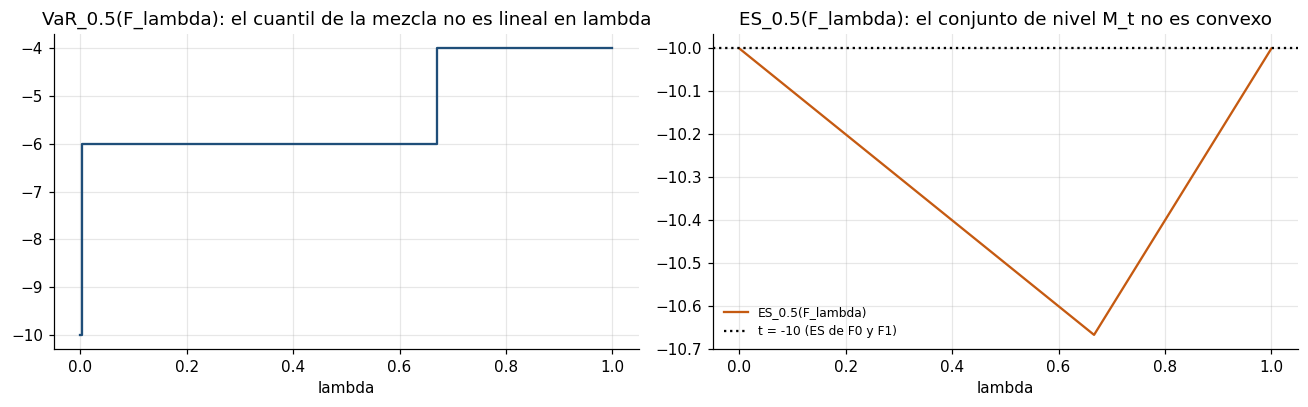

In [27]:
lams = np.linspace(0, 1, 301)
path = np.array([var_es_discrete(*mezcla(F0_d, F1_d, lam), 0.5) for lam in lams])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(lams, path[:, 0], color=C_HS, drawstyle="steps-post")
ax[0].set_title("VaR_0.5(F_lambda): el cuantil de la mezcla no es lineal en lambda")
ax[0].set_xlabel("lambda")
ax[1].plot(lams, path[:, 1], color=C_N, label="ES_0.5(F_lambda)")
ax[1].axhline(-10, color="k", ls=":", label="t = -10 (ES de F0 y F1)")
ax[1].set_title("ES_0.5(F_lambda): el conjunto de nivel M_t no es convexo")
ax[1].set_xlabel("lambda")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** Para cualquier $\lambda \in (0, 1)$, la mezcla tiene un ES distinto de $-10$. Con $\lambda = 0{,}5$, la masa acumulada hasta $-10$ es $0{,}125 + 0{,}25 = 0{,}375 < 0{,}5$, el cuantil de la mezcla salta a $-6$ y la cola de la mezcla integra $0{,}125 \cdot (-16) + 0{,}25 \cdot (-10) + 0{,}125 \cdot (-6) = -5{,}25$, de modo que $\mathrm{ES}_{0.5}(F_{0.5}) = -10{,}5$. Con $\lambda = 0{,}4$ resulta $-10{,}4$. En general, $\mathrm{ES}_{0.5}(F_\lambda) = -10 - \lambda$ mientras el cuantil está en $-6$ ($\lambda \le 2/3$) y $-12 + 2\lambda$ cuando pasa a $-4$.

El mecanismo es el del paso 4: el valor $-6$ de $F_0$, que no pertenece a su cola, queda por debajo del $-4$ de la cola de $F_1$. Al mezclar, el orden de las masas cambia y la cola de la mezcla incluye a $-6$ en lugar de $-4$. Si las colas de $F_0$ y $F_1$ estuvieran siempre por debajo del resto de la masa de ambas (por ejemplo, con $F_0$ en $\{-10, 0\}$), la cola de la mezcla sería la mezcla de las colas y el ES se conservaría: un contraejemplo necesita que las masas se entrecrucen.

Como el conjunto de nivel $M_{-10}$ no es convexo, no existe ninguna función de scoring estrictamente consistente para el ES aislado.

**Ejemplo continuo.** Lo mismo ocurre con distribuciones normales, en la convención de rendimientos y con $\alpha = 0{,}05$. Para calcular VaR y ES de una distribución continua cualquiera se resuelve $F(x_1) = \alpha$ y se usa la identidad que resulta de integrar por partes la cola,

$$
E\big[\mathbf{1}\{Y \le x_1\}(x_1 - Y)\big] = \int_{-\infty}^{x_1} F(y)\,dy
\quad\Longrightarrow\quad
\mathrm{ES}_\alpha(F) = x_1 - \frac{1}{\alpha}\int_{-\infty}^{x_1} F(y)\,dy, \qquad x_1 = \mathrm{VaR}_\alpha(F).
$$

La función `var_es_from_cdf` implementa exactamente esta fórmula, que vuelve a aparecer en la prueba del Corolario 5.5. Se toman $F_1 = N(0,1)$, $F_2 = N(-1{,}031;\ 0{,}5^2)$, con el mismo ES que $F_1$, y $F_3 = N(-0{,}822;\ 0{,}5^2)$, con el mismo VaR que $F_1$.

In [28]:
def var_es_from_cdf(cdf, alpha, bracket=(-60.0, 60.0)):
    x1 = optimize.brentq(lambda y: cdf(y) - alpha, *bracket, xtol=1e-12)
    tail = integrate.quad(cdf, -np.inf, x1, limit=200)[0]
    return x1, x1 - tail / alpha


A_DEMO = 0.05
z_a = stats.norm.ppf(A_DEMO)
k_a = stats.norm.pdf(z_a) / A_DEMO
F1 = stats.norm(0, 1)
F2 = stats.norm(-k_a * 0.5, 0.5)
F3 = stats.norm(z_a * 0.5, 0.5)
mix12 = lambda y: 0.5 * F1.cdf(y) + 0.5 * F2.cdf(y)
mix13 = lambda y: 0.5 * F1.cdf(y) + 0.5 * F3.cdf(y)
pd.DataFrame({
    "F1 = N(0,1)": var_es_from_cdf(F1.cdf, A_DEMO),
    "F2 = N(%.3f, 0.5^2)" % F2.mean(): var_es_from_cdf(F2.cdf, A_DEMO),
    "Mezcla 0.5 F1 + 0.5 F2": var_es_from_cdf(mix12, A_DEMO),
    "F3 = N(%.3f, 0.5^2)" % F3.mean(): var_es_from_cdf(F3.cdf, A_DEMO),
    "Mezcla 0.5 F1 + 0.5 F3": var_es_from_cdf(mix13, A_DEMO),
}, index=["VaR_0.05 (x1)", "ES_0.05 (x2)"]).T

,VaR_0.05 (x1),ES_0.05 (x2)
"F1 = N(0,1)",-1.6449,-2.0627
"F2 = N(-1.031, 0.5^2)",-1.8538,-2.0627
Mezcla 0.5 F1 + 0.5 F2,-1.7940,-2.0772
"F3 = N(-0.822, 0.5^2)",-1.6449,-1.8538
Mezcla 0.5 F1 + 0.5 F3,-1.6449,-1.9582


$F_1$ y $F_2$ tienen el mismo ES ($-2{,}0627$), pero el de su mezcla es $-2{,}0772$. $F_1$ y $F_3$ comparten el VaR ($-1{,}6449$) y su mezcla lo conserva.

### 4.3 Elicitabilidad conjunta de (VaR, ES): Corolario 5.5

**Intuición.** La identidad anterior dice que, si se conoce el cuantil $x_1$, el ES es una esperanza: $\mathrm{ES}_\alpha = E\big[x_1 - \tfrac{1}{\alpha}\mathbf{1}\{Y \le x_1\}(x_1 - Y)\big]$. Las esperanzas son elicitables. La dificultad del ES aislado es que su cola depende del cuantil, y el cuantil se mueve de forma no lineal con las mezclas. La solución es reportar y puntuar el cuantil junto con el ES. Por eso el ES es **elicitable de orden 2**: no es 1-elicitable, pero es componente del funcional 2-elicitable $T(F) = \big(\mathrm{VaR}_\alpha(F), \mathrm{ES}_\alpha(F)\big)$.

**Resultado teórico (Fissler y Ziegel, 2016, Corolario 5.5).** Para $x = (x_1, x_2)$ en $A_0 = \{x_1 \ge x_2\}$, la función de scoring

$$
S(x_1, x_2, y) = \big(\mathbf{1}\{y \le x_1\} - \alpha\big)G_1(x_1) - \mathbf{1}\{y \le x_1\}\,G_1(y)
+ G_2(x_2)\Big(x_2 - x_1 + \tfrac{1}{\alpha}\,\mathbf{1}\{y \le x_1\}(x_1 - y)\Big) - \mathcal{G}_2(x_2) + a(y)
$$

es estrictamente $\mathcal{F}$-consistente para $(\mathrm{VaR}_\alpha, \mathrm{ES}_\alpha)$ si $G_1$ es creciente y $\mathcal{G}_2$ es estrictamente creciente y estrictamente convexa, con $\mathcal{G}_2' = G_2$ (es decir, $G_2 > 0$ y estrictamente creciente). $\mathcal{F}$ son las distribuciones con primer momento finito y cuantil $\alpha$ único, y $a(y)$ es cualquier función de $y$ que haga finito el score esperado; no afecta las comparaciones entre modelos.

**Idea decisiva de la prueba: $\bar S(x, F) - \bar S(t, F) = R_1 + R_2 \ge 0$.**

1. *Aislamiento del VaR.* $R_1 = \int_{t_1}^{x_1}(F(y) - \alpha)\,G_1'(y)\,dy$ es la diferencia de la pinball loss ponderada por $G_1$. Por la sección 4.1, $R_1 \ge 0$, y vale cero si $x_1 = t_1$.
2. *Anclaje de la cola.* En la parte del ES, $E\big[\mathbf{1}\{Y \le x_1\}(x_1 - Y)\big] = \int_{-\infty}^{x_1} F(y)\,dy$ (integración por partes). Usando que en el valor verdadero $t_2 - t_1 + \tfrac{1}{\alpha}\int_{-\infty}^{t_1}F(y)\,dy = 0$, el término entre paréntesis queda en $(x_2 - t_2) + \tfrac{1}{\alpha}\int_{t_1}^{x_1}(F(y) - \alpha)\,dy$.
3. *Distancia de Bregman.* Reordenando se obtiene la expresión de $R_2$ que aparece debajo de esta lista. Su primer término es la distancia de Bregman de $\mathcal{G}_2$, estrictamente positiva si $x_2 \ne t_2$ porque $\mathcal{G}_2$ es estrictamente convexa. El segundo es no negativo por el mismo argumento de signo de la pinball loss, porque $G_2 > 0$.
4. *Mínimo único.* Ambos términos se anulan solo en $x_1 = t_1$, $x_2 = t_2$.

$$
R_2 = \underbrace{\mathcal{G}_2(t_2) - \mathcal{G}_2(x_2) - G_2(x_2)(t_2 - x_2)}_{d_{\mathcal{G}_2}(t_2,\, x_2)\ \ge\ 0}
\;+\; \frac{G_2(x_2)}{\alpha}\int_{t_1}^{x_1}\big(F(y) - \alpha\big)\,dy .
$$

**El término $\tfrac{1}{\alpha}\mathbf{1}\{y \le x_1\}(x_1 - y)$ neutraliza el movimiento del cuantil.** La parte del ES tiene esperanza $\bar V_2(x, F) = x_2 - x_1 + \tfrac{1}{\alpha}\int_{-\infty}^{x_1}F(y)\,dy$, cuya derivada respecto a $x_1$ es $-1 + F(x_1)/\alpha$, que vale cero en $x_1 = t_1$. Un error pequeño en el VaR solo afecta al objetivo del ES en segundo orden. Además, para $x_1$ fijo, $\bar V_2$ es lineal en $F$, así que la no linealidad que rompía al ES aislado desaparece cuando el cuantil se reporta junto con él.

**Verificación numérica de la descomposición.** Se toma $Y \sim t_4$ con localización $-0{,}05$ y escala $0{,}8$ (colas pesadas, parecidas a las de los datos) y el miembro de la familia que se usará en el resto del notebook: $G_1 \equiv 0$ (luego $R_1 = 0$), $\mathcal{G}_2(x_2) = -\ln(-x_2)$ y $G_2(x_2) = -1/x_2$ (sección 4.5). Para varios reportes $x$ se compara $\bar S(x, F) - \bar S(t, F)$, calculado directamente, con $R_1 + R_2$.

In [29]:
A_T = 0.05
Ft = stats.t(4, loc=-0.05, scale=0.8)
t1, t2 = var_es_from_cdf(Ft.cdf, A_T)


def G2(x2):
    return -1 / x2


def calG2(x2):
    return -np.log(-x2)


def tail_int(x1, dist=Ft):
    return integrate.quad(dist.cdf, -np.inf, x1, limit=200, epsabs=1e-13, epsrel=1e-13)[0]


def Sbar_fz0(x1, x2, dist=Ft, alpha=A_T):
    if x2 >= 0 or x1 < x2:
        return np.inf
    return G2(x2) * (x2 - x1 + tail_int(x1, dist) / alpha) - calG2(x2)


rows = {}
for x1, x2 in [(t1, t2), (t1 - 0.3, t2), (t1, t2 - 0.4), (t1 + 0.3, t2 + 0.2), (t1 - 0.5, t2 + 0.3)]:
    bregman = calG2(t2) - calG2(x2) - G2(x2) * (t2 - x2)
    cross = G2(x2) / A_T * integrate.quad(lambda y: Ft.cdf(y) - A_T, t1, x1, epsabs=1e-13)[0]
    rows[f"x = ({x1:.3f}, {x2:.3f})"] = {"S̄(x,F) - S̄(t,F)": Sbar_fz0(x1, x2) - Sbar_fz0(t1, t2),
                                         "R1": 0.0, "Bregman d(t2, x2)": bregman,
                                         "término cruzado": cross, "R1 + R2": bregman + cross}
pd.DataFrame(rows).T

,"S̄(x,F) - S̄(t,F)",R1,"Bregman d(t2, x2)",término cruzado,R1 + R2
"x = (-1.755, -2.612)",0.0000,0.0000,0.0000,0.0000,0.0000
"x = (-2.055, -2.612)",0.0209,0.0000,0.0000,0.0209,0.0209
"x = (-1.755, -3.012)",0.0097,0.0000,0.0097,0.0000,0.0097
"x = (-1.455, -2.412)",0.0341,0.0000,0.0033,0.0308,0.0341
"x = (-2.255, -2.312)",0.0674,0.0000,0.0078,0.0597,0.0674


La primera fila es el valor verdadero $t = (-1{,}7555;\ -2{,}6123)$, donde todo vale cero. En las demás, la diferencia de score esperado coincide con $R_1 + R_2$, y tanto la distancia de Bregman como el término cruzado son no negativos. Cuando solo se equivoca el VaR (segunda fila), la Bregman es cero y toda la penalización viene del término cruzado. Cuando solo se equivoca el ES (tercera fila), el término cruzado es cero.

**Ilustración: los conjuntos de nivel del par sí son convexos.** Se construye una $t$ de Student con 4 grados de libertad, desplazada y escalada para tener exactamente el mismo VaR y el mismo ES que $N(0,1)$ con $\alpha = 0{,}05$. Para una $t_\nu$ estándar, $\mathrm{ES}_\alpha = -\dfrac{f_\nu(q)\,(\nu + q^2)}{(\nu - 1)\,\alpha}$, con $q = t_\nu^{-1}(\alpha)$.

In [30]:
nu = 4
q_t = stats.t.ppf(A_DEMO, nu)
es_t_std = -stats.t.pdf(q_t, nu) * (nu + q_t**2) / ((nu - 1) * A_DEMO)
x1_n, x2_n = var_es_from_cdf(F1.cdf, A_DEMO)
s4 = (x2_n - x1_n) / (es_t_std - q_t)
m4 = x1_n - s4 * q_t
F4 = stats.t(nu, loc=m4, scale=s4)
mix14 = lambda y: 0.5 * F1.cdf(y) + 0.5 * F4.cdf(y)
pd.DataFrame({
    "F1 = N(0,1)": var_es_from_cdf(F1.cdf, A_DEMO),
    "F4 = t_4 (loc %.3f, escala %.3f)" % (m4, s4): var_es_from_cdf(F4.cdf, A_DEMO),
    "Mezcla 0.5 F1 + 0.5 F4": var_es_from_cdf(mix14, A_DEMO),
}, index=["VaR_0.05 (x1)", "ES_0.05 (x2)"]).T

,VaR_0.05 (x1),ES_0.05 (x2)
"F1 = N(0,1)",-1.6449,-2.0627
"F4 = t_4 (loc -0.813, escala 0.390)",-1.6449,-2.0627
Mezcla 0.5 F1 + 0.5 F4,-1.6449,-2.0627


La mezcla conserva el VaR y el ES. La razón es exacta: en el cuantil común $x_1$, la mezcla cumple $F_\lambda(x_1) = \alpha$, y $\int_{-\infty}^{x_1}F_\lambda(y)\,dy$ es lineal en $\lambda$, así que el ES de la mezcla es el mismo. La condición necesaria de Osband se cumple para el par, y el Corolario 5.5 muestra que es suficiente.

### 4.4 Principio de Osband y función de identificación

El Corolario 5.5 no solo da *una* familia de funciones consistentes: en el artículo, esa familia sale de una caracterización basada en el principio de Osband.

**Función de identificación.** $V(x, y)$ es una función de identificación estricta para $T$ si $\bar V(x, F) = E_F[V(x, Y)] = 0$ si y solo si $x = T(F)$. Para el par (VaR, ES):

$$
V(x, y) = \begin{pmatrix} V_1 \\ V_2 \end{pmatrix} = \begin{pmatrix} \mathbf{1}\{y \le x_1\} - \alpha \\[2pt] x_2 - x_1 + \dfrac{1}{\alpha}\,\mathbf{1}\{y \le x_1\}(x_1 - y) \end{pmatrix}.
$$

La identificabilidad sirve para estimar por momentos (GMM) y para el backtesting absoluto: la sección 3 contrastó justamente que $V_1$ tenga media cero.

**Resultado teórico (principio de Osband).** Si $S$ es estrictamente consistente y $V$ es una función de identificación estricta, bajo condiciones de regularidad existe una matriz $h(x)$ de $k \times k$ tal que

$$
\nabla_x \bar S(x, F) = h(x)\,\bar V(x, F) \qquad \text{para todo } x \text{ en el interior del dominio y toda } F \in \mathcal{F}.
$$

**Idea de la prueba.** Por la condición de primer orden, $\nabla_x \bar S(t, F) = 0$ en $t = T(F)$. Por identificabilidad estricta, $\bar V(x, F) = 0$ si y solo si $x = T(F)$. Entonces, para cada $x$ fijo, toda $F$ con $\bar V(x, F) = 0$ cumple también $\nabla_x \bar S(x, F) = 0$: el núcleo de $F \mapsto \bar V(x, F)$ está contenido en el núcleo de $F \mapsto \nabla_x \bar S(x, F)$. Si la familia $\mathcal{F}$ es lo bastante rica para que $\bar V(x, \cdot)$ tenga rango pleno, un argumento de álgebra lineal (rango-nulidad) obliga a que el gradiente sea una combinación lineal de las componentes de $\bar V$, con coeficientes $h(x)$.

**De $h(x)$ a la forma de la familia.** Como $\bar S$ es dos veces diferenciable, sus derivadas cruzadas deben coincidir (simetría del Hessiano). Al imponer esa simetría a $\nabla_x \bar S = h(x)\bar V$ con el $V$ de arriba, el artículo obtiene que $h$ es diagonal, que $h_{22}$ depende solo de $x_2$ y que $h_{11}$ se coordina con $G_1$. Para la familia del Corolario 5.5, derivando directamente:

$$
\partial_{x_1}\bar S = \Big(G_1'(x_1) + \frac{G_2(x_2)}{\alpha}\Big)\bar V_1, \qquad
\partial_{x_2}\bar S = G_2'(x_2)\,\bar V_2,
\qquad\text{es decir,}\qquad
h(x) = \begin{pmatrix} G_1'(x_1) + G_2(x_2)/\alpha & 0 \\ 0 & G_2'(x_2) \end{pmatrix}.
$$

Las condiciones del corolario ($G_1$ creciente, $G_2 > 0$ y creciente) hacen que $h$ tenga diagonal positiva, que es lo que garantiza un mínimo y no un punto de silla. Para el score FZ0 de la sección 4.5, $h_{11} = -1/(\alpha x_2)$ y $h_{22} = 1/x_2^2$.

**Verificación numérica.** Con la misma $t_4$, se calcula el gradiente de $\bar S$ por diferencias finitas y se compara con $h(x)\bar V(x, F)$.

In [31]:
def Vbar(x1, x2, dist=Ft, alpha=A_T):
    return np.array([dist.cdf(x1) - alpha, x2 - x1 + tail_int(x1, dist) / alpha])


eps = 1e-4
rows = {}
for x1, x2 in [(t1, t2), (t1 - 0.3, t2), (t1, t2 - 0.4), (t1 + 0.3, t2 + 0.2)]:
    grad = np.array([(Sbar_fz0(x1 + eps, x2) - Sbar_fz0(x1 - eps, x2)) / (2 * eps),
                     (Sbar_fz0(x1, x2 + eps) - Sbar_fz0(x1, x2 - eps)) / (2 * eps)])
    h = np.diag([-1 / (A_T * x2), 1 / x2**2])
    hv = h @ Vbar(x1, x2)
    rows[f"x = ({x1:.3f}, {x2:.3f})"] = {"V̄1": Vbar(x1, x2)[0], "V̄2": Vbar(x1, x2)[1],
                                         "dS̄/dx1 (dif. finitas)": grad[0], "(h V̄)_1": hv[0],
                                         "dS̄/dx2 (dif. finitas)": grad[1], "(h V̄)_2": hv[1]}
pd.DataFrame(rows).T

,V̄1,V̄2,dS̄/dx1 (dif. finitas),(h V̄)_1,dS̄/dx2 (dif. finitas),(h V̄)_2
"x = (-1.755, -2.612)",0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000
"x = (-2.055, -2.612)",-0.0169,0.0545,-0.1291,-0.1291,0.0080,0.0080
"x = (-1.755, -3.012)",0.0000,-0.4000,0.0000,0.0000,-0.0441,-0.0441
"x = (-1.455, -2.412)",0.0269,0.2744,0.2229,0.2229,0.0472,0.0472


En el valor verdadero, $\bar V = 0$ y el gradiente es cero. En los demás puntos, el gradiente numérico coincide con $h(x)\bar V(x, F)$ hasta el error de las diferencias finitas.

### 4.5 Score FZ0: implementación y M-estimación

**Elección del miembro.** Se usa $G_1 \equiv 0$ y $\mathcal{G}_2(x_2) = -\ln(-x_2)$ para $x_2 < 0$. Entonces $G_2(x_2) = -1/x_2 > 0$, y $\mathcal{G}_2$ es estrictamente creciente y estrictamente convexa en $(-\infty, 0)$, así que el score es estrictamente consistente. Con $a(y) = 0$ se obtiene la función FZ0 de Patton, Ziegel y Chen (2019):

$$
S_{FZ0}(x_1, x_2, y) = -\frac{1}{\alpha\,x_2}\,\mathbf{1}\{y \le x_1\}(x_1 - y) + \frac{x_1}{x_2} + \ln(-x_2) - 1, \qquad x_1 \ge x_2,\ x_2 < 0 .
$$

Con $v = -x_1$, $e = -x_2$ y $L = -y$, la misma función en pérdidas es

$$
S_{FZ0}(v, e, L) = \frac{\mathbf{1}\{L > v\}\,(L - v)}{\alpha\,e} + \frac{v}{e} + \ln e - 1, \qquad e > 0 .
$$

**Lectura de los términos (en pérdidas).**

- El primer término solo actúa en los días con excepción y penaliza el exceso de pérdida sobre el VaR en proporción al ES reportado. Un ES bajo hace caro cada exceso.
- Los términos $v/e + \ln e$ actúan todos los días. Para $v$ fijo, su derivada respecto a $e$ es $(e - v)/e^2 \ge 0$: reportar un ES más alto cuesta un poco cada día.
- El ES óptimo equilibra los dos efectos: lo bastante alto para cubrir los excesos y no más. Lo mismo ocurre con el VaR: subirlo reduce los excesos, pero aumenta $v/e$.

**Por qué este miembro.** Es homogéneo de grado cero: $S_{FZ0}(cv, ce, cL) = S_{FZ0}(v, e, L) + \ln c$. Las diferencias de score entre modelos no dependen de la escala, así que da lo mismo medir en porcentaje o en fracción. Nolde y Ziegel (2017) recomiendan funciones homogéneas para comparar modelos. La condición $x_2 < 0$ ($e > 0$) se cumple porque el ES de las pérdidas diarias es positivo en todos los pronósticos de ambos modelos (la función lanza un error si no fuera así).

In [32]:
def pinball(x1, y, alpha):
    return ((y <= x1).astype(float) - alpha) * (x1 - y)


def fz0_score(L, var, es, alpha):
    L, var, es = (np.asarray(x, dtype=float) for x in (L, var, es))
    if np.any(es <= 0):
        raise ValueError("FZ0 requiere ES > 0 en la convención de pérdidas")
    return (L > var) * (L - var) / (alpha * es) + var / es + np.log(es) - 1


def fz_general(y, x1, x2, alpha, G1, G2, calG2):
    ind = (y <= x1).astype(float)
    return (ind - alpha) * G1(x1) - ind * G1(y) + G2(x2) * (x2 - x1 + ind * (x1 - y) / alpha) - calG2(x2)

**Verificación 1: traducción de convenciones.** Se evalúa la fórmula general del Corolario 5.5, en la convención $(x_1, x_2, y)$, sobre los pronósticos HS con $\alpha = 0{,}05$, y se compara con la forma cerrada en pérdidas.

In [33]:
v_hs, e_hs = hs[0.05]["VaR"].to_numpy(), hs[0.05]["ES"].to_numpy()
s_closed = fz0_score(L_eval.to_numpy(), v_hs, e_hs, 0.05)
s_general = fz_general(-L_eval.to_numpy(), -v_hs, -e_hs, 0.05,
                       G1=lambda x: np.zeros_like(x), G2=G2, calG2=calG2)
pd.Series({"máx |FZ0 en pérdidas - fórmula general|": np.max(np.abs(s_closed - s_general))},
          name="Verificación").to_frame()

,Verificación
máx |FZ0 en pérdidas - fórmula general|,0.0000


Las dos expresiones coinciden en los 2.514 días: la traducción de signos y niveles es correcta.

**Verificación 2: el score esperado se minimiza en $t$.** Con la $t_4$ de la sección 4.3 se minimiza $\bar S_{FZ0}(x, F)$ sobre $(x_1, x_2)$. Como contraste, se minimiza también la pinball loss esperada, que debe recuperar solo el VaR.

In [34]:
opt = optimize.minimize(lambda x: Sbar_fz0(x[0], x[1]), x0=[-1.0, -1.5], method="Nelder-Mead",
                        options={"xatol": 1e-9, "fatol": 1e-12, "maxiter": 5000})
opt_q = optimize.minimize_scalar(lambda x1: integrate.quad(lambda y: pinball(x1, np.array(y), A_T) * Ft.pdf(y),
                                                           -np.inf, np.inf, limit=200)[0],
                                 bounds=(-5, 0), method="bounded", options={"xatol": 1e-10})
pd.DataFrame({
    "t verdadero": [t1, t2],
    "argmin S̄_FZ0": opt.x,
    "argmin pinball esperada": [opt_q.x, np.nan],
}, index=["x1 (VaR_0.05)", "x2 (ES_0.05)"])

,t verdadero,argmin S̄_FZ0,argmin pinball esperada
x1 (VaR_0.05),-1.7555,-1.7555,-1.7556
x2 (ES_0.05),-2.6123,-2.6123,NaN


El minimizador numérico coincide con $t = (-1{,}7555;\ -2{,}6123)$ y la pinball loss recupera el VaR. La figura muestra la forma de $\bar S_{FZ0}$ alrededor del óptimo.

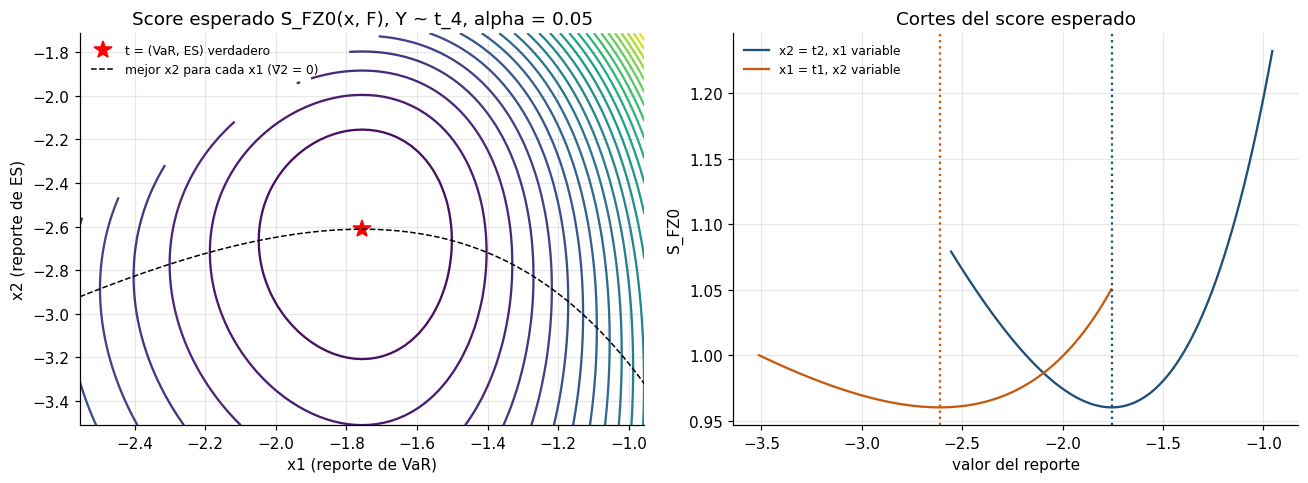

In [35]:
xx1 = np.linspace(t1 - 0.8, t1 + 0.8, 81)
xx2 = np.linspace(t2 - 0.9, t2 + 0.9, 81)
I1 = np.array([tail_int(x1) for x1 in xx1])
Z = np.array([[G2(x2) * (x2 - x1 + I / A_T) - calG2(x2) if x1 >= x2 else np.nan
               for x1, I in zip(xx1, I1)] for x2 in xx2])
x2_star = xx1 - I1 / A_T

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].contour(xx1, xx2, Z, levels=25, cmap="viridis")
ax[0].plot(t1, t2, "r*", ms=12, label="t = (VaR, ES) verdadero")
ax[0].plot(xx1, x2_star, color="k", lw=1, ls="--", label="mejor x2 para cada x1 (V̄2 = 0)")
ax[0].set_xlabel("x1 (reporte de VaR)")
ax[0].set_ylabel("x2 (reporte de ES)")
ax[0].set_title("Score esperado S̄_FZ0(x, F), Y ~ t_4, alpha = 0.05")
ax[0].legend(fontsize=8, loc="upper left")
ax[1].plot(xx1, Z[np.argmin(np.abs(xx2 - t2))], color=C_HS, label="x2 = t2, x1 variable")
ax[1].plot(xx2, Z[:, np.argmin(np.abs(xx1 - t1))], color=C_N, label="x1 = t1, x2 variable")
ax[1].axvline(t1, color=C_HS, ls=":")
ax[1].axvline(t2, color=C_N, ls=":")
ax[1].set_xlabel("valor del reporte")
ax[1].set_ylabel("S̄_FZ0")
ax[1].set_title("Cortes del score esperado")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura (resultado teórico ilustrado).**

- *Panel izquierdo.* Las curvas de nivel rodean un único mínimo en $t$ (estrella). Los reportes con $x_1 < x_2$ quedan fuera de $A_0$ y no se dibujan. La línea punteada es el mejor $x_2$ para cada $x_1$, que resuelve $\bar V_2 = 0$: $x_2^*(x_1) = x_1 - \tfrac{1}{\alpha}\int_{-\infty}^{x_1}F(y)\,dy$. Su máximo es $t_2$ y se alcanza en $x_1 = t_1$: con un VaR equivocado, el mejor ES que se puede reportar es más extremo que el verdadero. Cerca de $t_1$ la curva es plana, que es la neutralización del cuantil descrita en la sección 4.3.
- *Panel derecho.* Ambos cortes tienen su mínimo en el valor verdadero y son asimétricos: reportar un VaR o un ES menos extremo que el verdadero (más cerca de cero) aumenta el score más rápido que reportarlo más extremo en la misma magnitud.

**Verificación 3: M-estimación. HS minimiza el score empírico.** La elicitabilidad implica que minimizar el score empírico $\tfrac{1}{n}\sum_i S(x, y_i)$ produce M-estimadores del funcional, y la identificabilidad, que $\tfrac{1}{n}\sum_i V(x, y_i) = 0$ define estimadores de momentos. Si se toma como $F$ la distribución empírica de una ventana, el M-estimador del score FZ0 debería ser el estimador de simulación histórica. Se comprueba en la primera ventana, en pérdidas, junto con los momentos de identificación en el estimador HS.

In [36]:
def empirical_fz0_argmin(w, alpha):
    v0 = np.quantile(w, 1 - alpha)
    e0 = w[w > v0].mean()
    obj = lambda p: np.mean(fz0_score(w, p[0], p[1], alpha)) if p[1] > 0 else np.inf
    best = optimize.minimize(obj, x0=[v0 * 1.1, e0 * 0.9], method="Nelder-Mead",
                             options={"xatol": 1e-10, "fatol": 1e-14, "maxiter": 10_000})
    return best.x, best.fun


rows = {}
for a in LEVELS:
    w = w0.to_numpy()
    v_hs0, e_hs0 = var_es_hs(w, a)
    (v_opt, e_opt), f_opt = empirical_fz0_argmin(w, a)
    xs = np.sort(w)
    k = int(np.ceil(WINDOW * (1 - a) - 1e-9))
    rows[nivel(a)] = {"v HS = L_(k)": v_hs0, "L_(k+1)": xs[k], "v que minimiza": v_opt,
                      "e HS": e_hs0, "e que minimiza": e_opt,
                      "FZ0 en HS": np.mean(fz0_score(w, v_hs0, e_hs0, a)), "FZ0 mínima": f_opt,
                      "media V1 en HS": np.mean(w > v_hs0) - a,
                      "media V2 en HS": e_hs0 - v_hs0 - np.mean((w - v_hs0) * (w > v_hs0)) / a}
pd.DataFrame(rows).T

,v HS = L_(k),L_(k+1),v que minimiza,e HS,e que minimiza,FZ0 en HS,FZ0 mínima,media V1 en HS,media V2 en HS
95%,1.4165,1.4762,1.4431,2.0355,2.0355,0.7107,0.7107,0.0000,-0.0000
99%,2.1567,2.2763,2.2194,3.0413,3.0413,1.1123,1.1123,0.0000,0.0000


El ES que minimiza el score coincide exactamente con el de HS, y el score mínimo es el de HS. El VaR óptimo (1,4431 al 95 %) no coincide con el de HS (1,4165), pero cae dentro del intervalo $[L_{(k)}, L_{(k+1)})$, que es el conjunto de $\alpha$-cuantiles de la distribución empírica (sección 2.2). HS toma el extremo izquierdo. El ES no depende de cuál se elija: al mover $v$ dentro del intervalo, el cambio en $v$ se compensa exactamente con el de $E[(L - v)_+]/\alpha$. Los momentos de identificación son cero (en pérdidas, $V_1$ se evalúa como $\mathbf{1}\{L > v\} - \alpha$, que para distribuciones continuas es equivalente).

La simulación histórica es, por tanto, el M-estimador del score FZ0 sobre la ventana. Esto conecta el método tradicional con el marco de Fissler y Ziegel.

**Verificación 4: cuánto ruido tiene el score promedio en una muestra finita.** Se simulan 2.000 muestras de 2.500 días (aproximadamente el tamaño de la muestra de evaluación) de la misma $t_4$. En cada una se comparan los scores promedio del reporte verdadero y de reportes distorsionados en ±10 % ("|VaR| +10 %" significa un VaR 10 % más extremo).

In [37]:
nsim, T_mc = 2000, 2500
draws = Ft.rvs(size=(nsim, T_mc), random_state=rng)
cands = {"Verdadero": (t1, t2), "|VaR| +10%": (1.1 * t1, t2), "|ES| +10%": (t1, 1.1 * t2),
         "|VaR| -10%": (0.9 * t1, t2), "|ES| -10%": (t1, 0.9 * t2), "Ambos +10%": (1.1 * t1, 1.1 * t2)}
mc_scores = pd.DataFrame({k: fz0_score(-draws, -x1, -x2, A_T).mean(axis=1) for k, (x1, x2) in cands.items()})
pd.DataFrame({
    "Score medio": mc_scores.mean(),
    "Diferencia vs verdadero": mc_scores.mean() - mc_scores["Verdadero"].mean(),
    "% simulaciones en que gana el verdadero": [np.nan] + [np.mean(mc_scores["Verdadero"] < mc_scores[c]) for c in list(cands)[1:]],
})

,Score medio,Diferencia vs verdadero,% simulaciones en que gana el verdadero
Verdadero,0.9603,0.0000,NaN
|VaR| +10%,0.9679,0.0076,0.9170
|ES| +10%,0.9647,0.0044,0.8460
|VaR| -10%,0.9693,0.0090,0.9325
|ES| -10%,0.9661,0.0058,0.8740
Ambos +10%,0.9716,0.0113,0.9065


En promedio sobre las simulaciones, el reporte verdadero tiene el menor score y cualquier distorsión lo aumenta entre 0,004 y 0,011. Sin embargo, en una sola muestra de 2.500 días el verdadero gana solo entre el 85 % y el 93 % de las veces. Dos modelos razonables pueden ordenarse al revés por puro azar muestral. Por eso, además de comparar promedios, hay que contrastar si la diferencia es estadísticamente significativa (sección 4.7).

### 4.6 Segundo modelo: VaR y ES paramétricos bajo normalidad

**Intuición.** El segundo modelo usa exactamente la misma información que HS, las últimas 500 observaciones, pero supone normalidad con la media y la desviación estándar de la ventana. La comparación aísla entonces el efecto del supuesto distribucional: los dos modelos ven los mismos datos y solo difieren en cómo los convierten en VaR y ES.

**Formulación.** Con $\hat\mu_t$ y $\hat\sigma_t$ la media y la desviación estándar muestral (con $n - 1$ en el denominador) de las pérdidas $\{L_{t-500}, \dots, L_{t-1}\}$, y $L_t \sim N(\hat\mu_t, \hat\sigma_t^2)$:

$$
v_{\alpha,t} = \hat\mu_t + \hat\sigma_t\, z_{1-\alpha}, \qquad
e_{\alpha,t} = \hat\mu_t + \hat\sigma_t\,\frac{\varphi(z_{1-\alpha})}{\alpha},
$$

donde $z_{1-\alpha} = \Phi^{-1}(1-\alpha)$ y $\varphi$ es la densidad normal estándar. En la convención de rendimientos, $x_1 = -v$ y $x_2 = -e$. La fórmula del ES sale de $E[Z \mid Z > z] = \varphi(z)/(1 - \Phi(z))$ para $Z \sim N(0,1)$. Los factores son $z_{0.95} = 1{,}645$ y $\varphi(z_{0.95})/0{,}05 = 2{,}063$; $z_{0.99} = 2{,}326$ y $\varphi(z_{0.99})/0{,}01 = 2{,}665$. La razón ES/VaR (con $\mu = 0$) es 1,25 con $\alpha = 0{,}05$ y solo 1,15 con $\alpha = 0{,}01$: bajo normalidad, la cola más allá del VaR es corta.

In [38]:
def normal_var_es(mu, sd, alpha):
    z = stats.norm.ppf(1 - alpha)
    return mu + sd * z, mu + sd * stats.norm.pdf(z) / alpha


norm_fc = {}
for a in LEVELS:
    out = []
    for t in pos:
        w = Lv[t - WINDOW:t]
        out.append(normal_var_es(w.mean(), w.std(ddof=1), a))
    norm_fc[a] = pd.DataFrame(np.array(out), index=dates, columns=["VaR", "ES"])

**Verificación independiente** sobre la primera ventana: la fórmula cerrada se compara con (i) `var_es_from_cdf` aplicada a la distribución de $Y = -L$, es decir, búsqueda del cuantil más la integral $\int_{-\infty}^{x_1}F$, con cambio de signo, (ii) la integral de la función cuantil, $\tfrac{1}{\alpha}\int_{1-\alpha}^1 (\hat\mu + \hat\sigma\,\Phi^{-1}(u))\,du$, y (iii) Monte Carlo con 4 millones de simulaciones. También se confirma que el primer valor de la serie de pronósticos coincide.

In [39]:
chk = {}
for a in LEVELS:
    mu0, sd0 = w0.mean(), w0.std(ddof=1)
    v_cf, e_cf = normal_var_es(mu0, sd0, a)
    x1_num, x2_num = var_es_from_cdf(stats.norm(-mu0, sd0).cdf, a)
    e_quad = integrate.quad(lambda u: mu0 + sd0 * stats.norm.ppf(u), 1 - a, 1)[0] / a
    sims = stats.norm(mu0, sd0).rvs(4_000_000, random_state=rng)
    chk[nivel(a)] = {"v fórmula": v_cf, "v = -x1 numérico": -x1_num, "e fórmula": e_cf,
                     "e = -x2 numérico": -x2_num, "e integral cuantil": e_quad,
                     "e Monte Carlo": sims[sims > v_cf].mean(),
                     "v serie (1.er día)": norm_fc[a]["VaR"].iloc[0], "e serie (1.er día)": norm_fc[a]["ES"].iloc[0]}
pd.DataFrame(chk).T

,v fórmula,v = -x1 numérico,e fórmula,e = -x2 numérico,e integral cuantil,e Monte Carlo,v serie (1.er día),e serie (1.er día)
95%,1.3735,1.3735,1.7299,1.7299,1.7299,1.7302,1.3735,1.7299
99%,1.9547,1.9547,2.2436,2.2436,2.2436,2.2444,1.9547,2.2436


Las cuatro formas de calcular el ES coinciden; la de Monte Carlo difiere en la cuarta cifra decimal, como corresponde al error de simulación.

In [40]:
resumen_pronosticos(norm_fc)

Media  Desv. est.  Mínimo  Máximo  Último
95% VaR 1.7320      0.5030  0.8651  2.6872  1.6087
    ES  2.1845      0.6306  1.1081  3.3784  2.0377
99% VaR 2.4699      0.7112  1.2614  3.8146  2.3083
    ES  2.8369      0.8148  1.4585  4.3751  2.6561

**Hallazgo empírico.** Al 95 %, el VaR normal promedia 1,73 %, casi igual al de HS (1,71 %), pero su ES promedia 2,18 %, un 19 % menos que el de HS (2,69 %). Al 99 % la brecha se amplía: el VaR normal promedia 2,47 % frente a 3,16 % de HS (−22 %) y el ES 2,84 % frente a 4,41 % (−36 %). Es lo que anticipaba el análisis de colas de la sección 1.3: con la misma información, la normal coincide con HS cerca de $\alpha = 0{,}05$ y queda corta más allá.

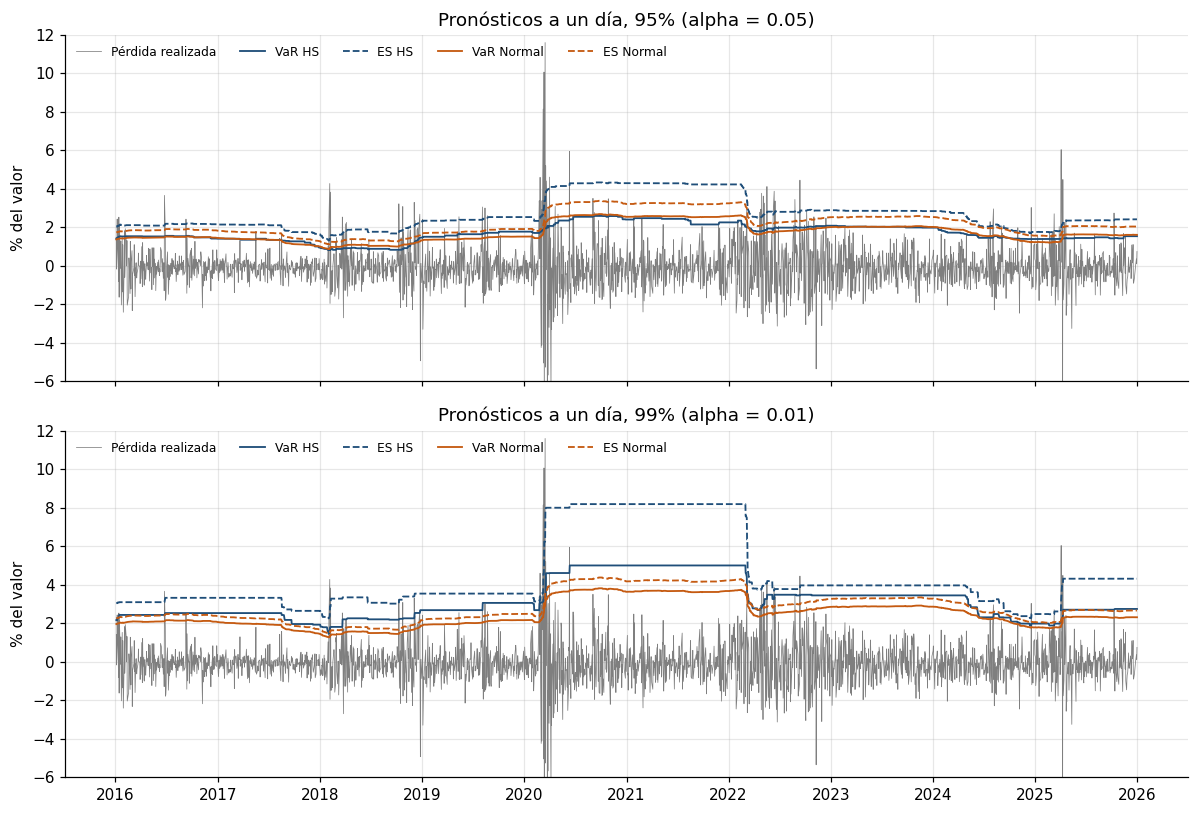

In [41]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, a in zip(axes, LEVELS):
    ax.plot(L_eval, color=C_L, lw=0.5, label="Pérdida realizada")
    ax.plot(hs[a]["VaR"], color=C_HS, lw=1.2, label="VaR HS")
    ax.plot(hs[a]["ES"], color=C_HS, lw=1.2, ls="--", label="ES HS")
    ax.plot(norm_fc[a]["VaR"], color=C_N, lw=1.2, label="VaR Normal")
    ax.plot(norm_fc[a]["ES"], color=C_N, lw=1.2, ls="--", label="ES Normal")
    ax.set_ylim(-6, 12)
    ax.set_ylabel("% del valor")
    ax.set_title(f"Pronósticos a un día, {nivel(a)} (alpha = {a})")
    ax.legend(loc="upper left", fontsize=8, ncol=5)
plt.tight_layout()
plt.show()

**Lectura.** Las series normales son más suaves porque dependen de $\hat\sigma_t$, que cambia un poco con cada observación nueva, mientras que HS cambia a saltos. Al 95 %, los dos VaR casi se superponen y la diferencia está en el ES. Al 99 %, el VaR y el ES de HS quedan por encima de los normales durante casi toda la muestra; tras marzo de 2020 la distancia entre los ES llega a unos 4 puntos porcentuales.

**Backtesting del modelo normal** con las mismas funciones de la sección 3, junto a los resultados de HS:

In [42]:
bt_n = backtest_table(norm_fc, "Normal")
bt_all = pd.concat([bt_hs, bt_n])
bt_all[COLS_UC]

excepciones  esperadas  tasa observada  alpha   LR_uc   p_uc  p binomial exacta  p_uc MC
HS     95%     125.0000   125.7000          0.0497 0.0500  0.0041 0.9489             1.0000   0.9630
       99%      41.0000    25.1400          0.0163 0.0100  8.4885 0.0036             0.0034   0.0051
Normal 95%     128.0000   125.7000          0.0509 0.0500  0.0440 0.8338             0.8190   0.8548
       99%      71.0000    25.1400          0.0282 0.0100 56.5575 0.0000             0.0000   0.0000

In [43]:
bt_all[COLS_CC]

n01     n11   pi01   pi11  LR_ind  p_ind  p_ind MC   LR_cc   p_cc  p_cc MC
HS     95% 106.0000 19.0000 0.0444 0.1520 19.8103 0.0000    0.0001 19.8138 0.0000   0.0001
       99%  36.0000  5.0000 0.0146 0.1220 12.4262 0.0004    0.0001 20.9275 0.0000   0.0000
Normal 95% 107.0000 20.0000 0.0449 0.1562 21.3133 0.0000    0.0001 21.3285 0.0000   0.0001
       99%  61.0000 10.0000 0.0250 0.1408 18.0965 0.0000    0.0000 74.6911 0.0000   0.0000

**Hallazgo empírico.**

- Con $\alpha = 0{,}05$, el modelo normal tiene 128 excepciones (5,09 %) y pasa la prueba de Kupiec (p-valor de 0,83). En cobertura incondicional al 95 %, HS y normal son indistinguibles.
- Con $\alpha = 0{,}01$, el normal tiene 71 excepciones frente a 25,1 esperadas (2,82 %, casi el triple). $LR_{uc} = 56{,}6$ y se rechaza con p-valor prácticamente nulo. HS también se rechaza en ese nivel, pero su exceso es mucho menor (41 excepciones, 1,63 %).
- La independencia se rechaza para ambos modelos en ambos niveles ($\hat\pi_{11}$ entre 12 % y 16 %). Los dos usan la misma ventana sin ponderar y heredan el mismo problema de agrupamiento.

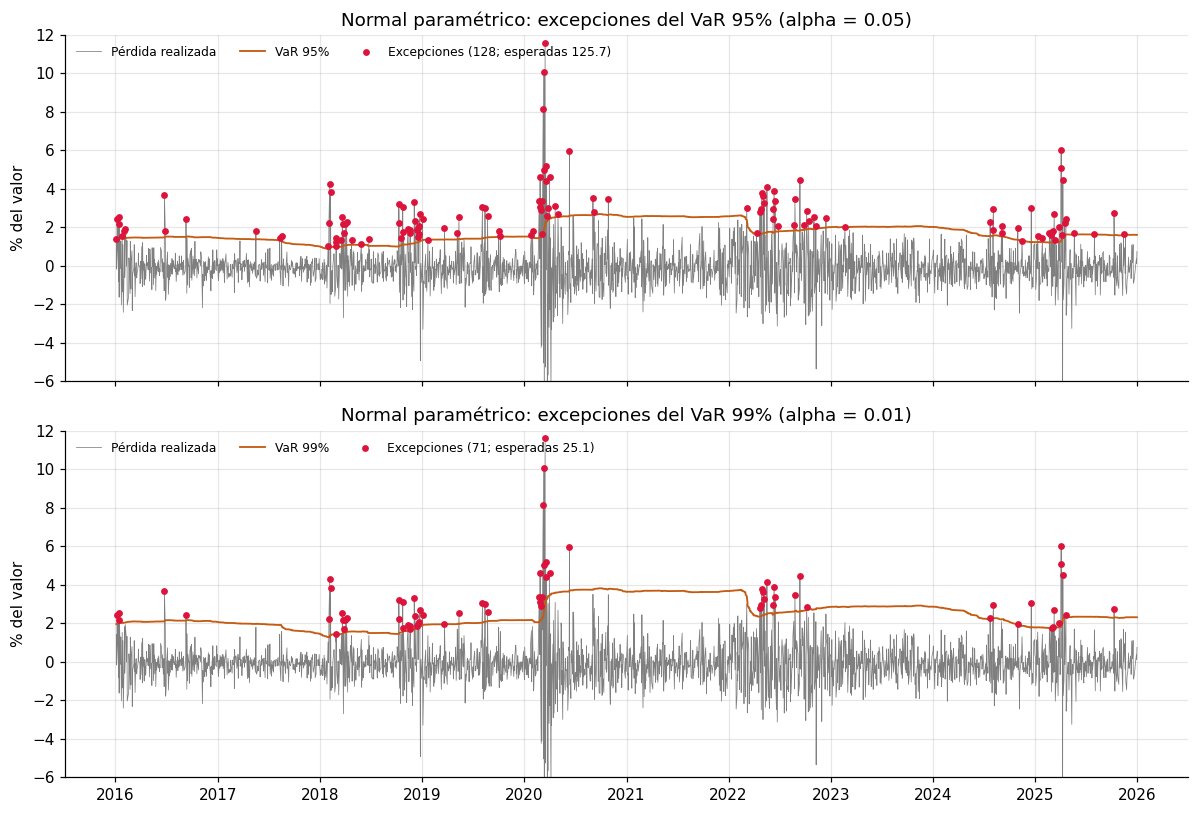

In [44]:
plot_violations(norm_fc, "Normal paramétrico", C_N)

In [45]:
pd.concat([hits_by_year(hs, "HS"), hits_by_year(norm_fc, "Normal")], axis=1)

HS     Normal    
     95% 99%    95% 99%
Date                   
2016   8   3     10   5
2017   3   0      3   0
2018  33  10     32  22
2019   8   1     10   6
2020  23  11     23  13
2021   2   0      0   0
2022  23   8     22  12
2023   0   0      1   0
2024   7   2      8   4
2025  18   6     19   9

**Lectura.** Al 95 %, los patrones anuales de excepciones de ambos modelos son casi idénticos. Al 99 %, el normal acumula 22 excepciones en 2018 (se esperaban 2,5), 13 en 2020 y 12 en 2022. En los episodios de estrés su VaR queda por debajo de pérdidas que HS sí cubre.

### 4.7 Ranking de modelos con Diebold-Mariano

Para cada modelo $m \in \{HS, N\}$ y día $t$ se calcula el score $S_t^{(m)} = S_{FZ0}\big(\hat x_{1t}^{(m)}, \hat x_{2t}^{(m)}, y_t\big)$ y su promedio $\bar S^{(m)} = \tfrac{1}{T}\sum_t S_t^{(m)}$. **Menor es mejor.** El diferencial de scoring es

$$
\Delta S_t = S\big(\hat x_{1t}^{(HS)}, \hat x_{2t}^{(HS)}, y_t\big) - S\big(\hat x_{1t}^{(N)}, \hat x_{2t}^{(N)}, y_t\big).
$$

**Prueba de Diebold y Mariano (1995).** Contrasta $H_0: E[\Delta S_t] = 0$ (igual capacidad predictiva) con

$$
DM = \frac{\overline{\Delta S}}{\sqrt{\hat\sigma^2_{HAC}/T}} \;\overset{H_0}{\to}\; N(0,1), \qquad
\hat\sigma^2_{HAC} = \hat\gamma_0 + 2\sum_{k=1}^{\ell}\Big(1 - \frac{k}{\ell+1}\Big)\hat\gamma_k ,
$$

donde $\hat\gamma_k$ es la autocovarianza muestral de orden $k$ de $\Delta S_t$. La varianza de largo plazo usa el estimador de Newey y West (1987) con núcleo de Bartlett, porque $\Delta S_t$ hereda el agrupamiento de volatilidad y no es independiente en el tiempo. El número de rezagos sigue la regla $\ell = \lfloor 4(T/100)^{2/9} \rfloor$, que da $\ell = 8$ para $T = 2.514$. Como los pronósticos salen de ventanas móviles de tamaño fijo, la prueba se interpreta en el marco de Giacomini y White (2006): compara los dos *métodos* de pronóstico, incluida la incertidumbre de estimación de cada ventana.

Se reportan el p-valor bilateral y el unilateral para $H_1: E[\Delta S_t] < 0$ (HS mejor). $DM < 0$ favorece a HS.

In [46]:
def dm_test(d, lag=None):
    d = np.asarray(d, dtype=float)
    T = d.size
    if lag is None:
        lag = int(np.floor(4 * (T / 100) ** (2 / 9)))
    u = d - d.mean()
    lrv = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    stat = d.mean() / np.sqrt(lrv / T)
    return {"media ΔS": d.mean(), "rezagos HAC": lag, "estadístico DM": stat,
            "p-valor bilateral": 2 * stats.norm.sf(abs(stat)), "p-valor unilateral (H1: ΔS < 0)": stats.norm.cdf(stat)}


scores = {}
for a in LEVELS:
    scores[a] = pd.DataFrame({
        "HS": fz0_score(L_eval, hs[a]["VaR"], hs[a]["ES"], a),
        "Normal": fz0_score(L_eval, norm_fc[a]["VaR"], norm_fc[a]["ES"], a),
    }, index=dates)

score_tab = {}
for a in LEVELS:
    s = scores[a]
    dm = dm_test(s["HS"] - s["Normal"])
    score_tab[nivel(a)] = {"FZ0 medio HS": s["HS"].mean(), "FZ0 medio Normal": s["Normal"].mean(), **dm,
                           "% días HS mejor": np.mean(s["HS"] < s["Normal"])}
score_tab = pd.DataFrame(score_tab).T
score_tab

,FZ0 medio HS,FZ0 medio Normal,media ΔS,rezagos HAC,estadístico DM,p-valor bilateral,p-valor unilateral (H1: ΔS < 0),% días HS mejor
95%,1.0928,1.1723,-0.0795,8.0000,-2.5043,0.0123,0.0061,0.2271
99%,1.7489,2.3317,-0.5827,8.0000,-2.7797,0.0054,0.0027,0.0278


**Hallazgo empírico.**

- Con $\alpha = 0{,}05$, el score FZ0 medio es 1,093 para HS y 1,172 para el normal ($\overline{\Delta S} = -0{,}080$). $DM = -2{,}50$, con p-valor bilateral de 0,012 (unilateral: 0,006). HS es significativamente mejor al 5 %.
- Con $\alpha = 0{,}01$, los scores son 1,749 y 2,332 ($\overline{\Delta S} = -0{,}583$). $DM = -2{,}78$, con p-valor bilateral de 0,005 (unilateral: 0,003).
- Sin embargo, HS tiene menor score solo en el 22,7 % de los días con $\alpha = 0{,}05$ y en el 2,8 % con $\alpha = 0{,}01$. El normal gana la mayoría de los días y HS gana el promedio. La descomposición siguiente explica por qué.

Con $\alpha = 0{,}05$, el ranking por FZ0 distingue a dos modelos que la calibración absoluta del VaR no separa (ambos pasan Kupiec). La diferencia viene del ES, que el backtesting clásico no evalúa.

*Verificación externa (opcional)* del estadístico DM con la regresión de $\Delta S_t$ sobre una constante y errores estándar HAC de `statsmodels`:

In [47]:
try:
    import statsmodels.api as sm
    rows = {}
    for a in LEVELS:
        d = (scores[a]["HS"] - scores[a]["Normal"]).to_numpy()
        res = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": 8, "use_correction": False})
        rows[nivel(a)] = {"DM propio": dm_test(d)["estadístico DM"], "t HAC statsmodels": float(res.tvalues[0])}
    print(pd.DataFrame(rows).T)
except ImportError:
    print("statsmodels no está instalado; se omite la verificación externa.")

     DM propio  t HAC statsmodels
95%    -2.5043            -2.5043
99%    -2.7797            -2.7797


In [48]:
decomp = {}
for a in LEVELS:
    for m, fc in (("HS", hs), ("Normal", norm_fc)):
        s = scores[a][m]
        h = L_eval > fc[a]["VaR"]
        decomp[(nivel(a), m)] = {"Días sin excepción": int((~h).sum()), "FZ0 medio sin excepción": s[~h].mean(),
                                 "Días con excepción": int(h.sum()), "FZ0 medio con excepción": s[h].mean(),
                                 "Aporte de días sin excepción": s[~h].sum() / len(s),
                                 "Aporte de días con excepción": s[h].sum() / len(s), "FZ0 medio total": s.mean()}
pd.DataFrame(decomp).T

Días sin excepción  FZ0 medio sin excepción  Días con excepción  FZ0 medio con excepción  Aporte de días sin excepción  \
95% HS              2,389.0000                   0.5950            125.0000                  10.6069                        0.5654   
    Normal          2,386.0000                   0.5402            128.0000                  12.9538                        0.5127   
99% HS              2,473.0000                   1.1546             41.0000                  37.5959                        1.1358   
    Normal          2,443.0000                   0.8780             71.0000                  52.3516                        0.8532   

            Aporte de días con excepción  FZ0 medio total  
95% HS                            0.5274           1.0928  
    Normal                        0.6595           1.1723  
99% HS                            0.6131           1.7489  
    Normal                        1.4785           2.3317

**Lectura.** El score medio de cada modelo se descompone en el aporte de sus días sin excepción y el de sus días con excepción (cada modelo con sus propias excepciones).

- En los días sin excepción, el normal puntúa mejor (0,540 frente a 0,595 al 95 %; 0,878 frente a 1,155 al 99 %). Su ES es más bajo y el término $v/e + \ln e$ cobra cada día por un ES alto.
- En los días con excepción ocurre lo contrario. El ES bajo del normal hace muy caro cada exceso: 12,95 frente a 10,61 puntos por excepción al 95 %, y 52,4 frente a 37,6 al 99 %. Al 99 %, las excepciones aportan 1,48 de los 2,33 puntos medios del normal y 0,61 de los 1,75 de HS.

FZ0 hace explícito el compromiso descrito en la sección 4.5: un ES alto se paga un poco todos los días y un ES bajo se paga mucho en los días malos. En esta muestra, los días malos pesan más.

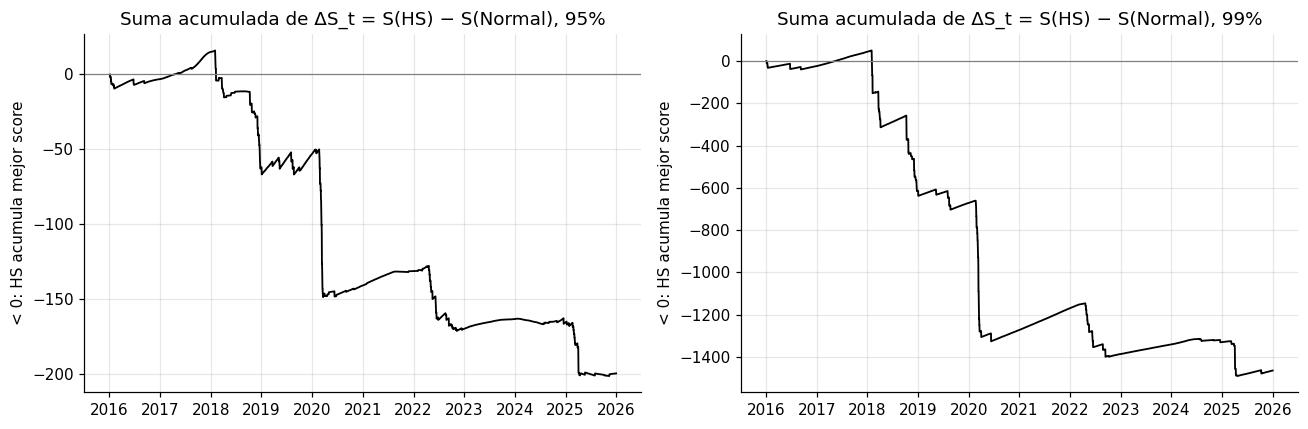

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, a in zip(axes, LEVELS):
    d = scores[a]["HS"] - scores[a]["Normal"]
    ax.plot(d.cumsum(), color="k", lw=1.2)
    ax.axhline(0, color=C_L, lw=0.8)
    ax.set_title(f"Suma acumulada de ΔS_t = S(HS) − S(Normal), {nivel(a)}")
    ax.set_ylabel("< 0: HS acumula mejor score")
plt.tight_layout()
plt.show()

**Lectura.** La suma acumulada de $\Delta S_t$ baja a saltos en febrero de 2018, en el cuarto trimestre de 2018, en marzo de 2020, durante 2022 y en abril de 2025. Entre esos episodios sube lentamente: en los periodos tranquilos el normal acumula pequeñas ventajas diarias. La ventaja de HS se gana en pocos días de estrés y se erosiona poco a poco en la calma.

In [50]:
yearly = pd.concat({nivel(a): scores[a].groupby(scores[a].index.year).mean() for a in LEVELS}, axis=1)
for a in LEVELS:
    yearly[(nivel(a), "ΔS = HS − Normal")] = yearly[(nivel(a), "HS")] - yearly[(nivel(a), "Normal")]
yearly.sort_index(axis=1)

95%                            99%                        
         HS Normal ΔS = HS − Normal     HS Normal ΔS = HS − Normal
Date                                                              
2016 0.7214 0.7349          -0.0135 1.1614 1.2549          -0.0935
2017 0.3773 0.3051           0.0721 0.8781 0.6096           0.2686
2018 1.6676 1.9748          -0.3072 2.1733 4.7943          -2.6210
2019 0.7662 0.7303           0.0360 1.1059 1.3353          -0.2294
2020 2.2675 2.6144          -0.3469 3.8357 6.2112          -2.3754
2021 1.0028 0.9645           0.0384 1.7128 1.3046           0.4082
2022 1.4106 1.5645          -0.1540 1.7874 2.6519          -0.8645
2023 0.7581 0.7318           0.0262 1.2459 1.0641           0.1819
2024 0.7444 0.7534          -0.0090 1.2677 1.2239           0.0438
2025 1.2062 1.3422          -0.1360 2.3117 2.8499          -0.5382

**Lectura.** La diferencia anual (columna $\Delta S$, negativa cuando gana HS) confirma el patrón. Al 95 %, HS gana en 2018, 2020, 2022 y 2025 por márgenes de 0,14 a 0,35, y en 2016 y 2024 por márgenes muy pequeños. El normal gana en 2017, 2019, 2021 y 2023 por márgenes de 0,03 a 0,07. Al 99 %, las ventajas de HS en 2018 (−2,62) y 2020 (−2,38) son de un orden de magnitud mayor que las del normal en sus mejores años (+0,41 en 2021).

**Diagnóstico descriptivo del ES.** Si el ES está bien especificado, la pérdida media en los días con excepción debería parecerse al ES reportado para esos días (idea de McNeil y Frey, 2000). Es la versión muestral de $\bar V_2 = 0$ restringida a los días de cola. La tabla no es una prueba formal, solo una comparación de magnitudes.

In [51]:
es_check = {}
for name, fc in (("HS", hs), ("Normal", norm_fc)):
    for a in LEVELS:
        hit = L_eval > fc[a]["VaR"]
        es_check[(name, nivel(a))] = {"Excepciones": int(hit.sum()),
                                      "Pérdida media en excepción": L_eval[hit].mean(),
                                      "ES medio reportado en esos días": fc[a]["ES"][hit].mean(),
                                      "Razón pérdida / ES": L_eval[hit].mean() / fc[a]["ES"][hit].mean()}
pd.DataFrame(es_check).T

Excepciones  Pérdida media en excepción  ES medio reportado en esos días  Razón pérdida / ES
HS     95%     125.0000                      2.7282                           2.4646              1.1070
       99%      41.0000                      3.9998                           3.7740              1.0598
Normal 95%     128.0000                      2.6685                           1.9031              1.4022
       99%      71.0000                      3.2992                           2.3672              1.3937

**Hallazgo empírico.** Cuando el VaR normal se supera, la pérdida promedio es un 40 % mayor que el ES que el modelo reportaba (razón de 1,40 al 95 % y 1,39 al 99 %). Para HS el desfase es de 11 % y 6 %. Ninguno de los dos captura del todo la severidad de la cola en los días de estrés, pero el normal la subestima mucho más. Esta es la razón directa de su peor score FZ0.

**Robustez.** Se revisa si la conclusión depende de (i) el número de rezagos HAC, (ii) el periodo, (iii) unos pocos días extremos y (iv) el miembro de la familia del Corolario 5.5. Para el punto (iv) se usa $G_1(x) = x$ en lugar de $G_1 \equiv 0$, con el mismo $\mathcal{G}_2$. Esa elección suma a FZ0 la pinball loss del VaR, $(\mathbf{1}\{y \le x_1\} - \alpha)(x_1 - y)$, más un término $-\alpha y$ que depende solo de $y$ y se cancela en $\Delta S_t$. La función resultante también es estrictamente consistente.

In [52]:
rob = {}
y_eval = -L_eval.to_numpy()
for a in LEVELS:
    lab = nivel(a)
    d = scores[a]["HS"] - scores[a]["Normal"]
    for lag in (0, 5, 8, 15, 30):
        rob[(lab, f"Rezagos HAC = {lag}")] = dm_test(d, lag)
    for name, mask in [("Sin 2020", d.index.year != 2020), ("2016-2019", d.index.year <= 2019),
                       ("2021-2025", d.index.year >= 2021),
                       ("Sin los 10 días más favorables a HS", ~d.index.isin(d.nsmallest(10).index))]:
        rob[(lab, name)] = dm_test(d[mask])
    d_alt = d + (pinball(-hs[a]["VaR"].to_numpy(), y_eval, a) - pinball(-norm_fc[a]["VaR"].to_numpy(), y_eval, a))
    rob[(lab, "Corolario 5.5 con G1(x) = x")] = dm_test(d_alt)
rob = pd.DataFrame(rob).T
rob

media ΔS  rezagos HAC  estadístico DM  p-valor bilateral  p-valor unilateral (H1: ΔS < 0)
95% Rezagos HAC = 0                       -0.0795       0.0000         -4.0833             0.0000                           0.0000
    Rezagos HAC = 5                       -0.0795       5.0000         -2.8006             0.0051                           0.0026
    Rezagos HAC = 8                       -0.0795       8.0000         -2.5043             0.0123                           0.0061
    Rezagos HAC = 15                      -0.0795      15.0000         -2.1554             0.0311                           0.0156
    Rezagos HAC = 30                      -0.0795      30.0000         -1.9337             0.0532                           0.0266
    Sin 2020                              -0.0495       7.0000         -2.4665             0.0136                           0.0068
    2016-2019                             -0.0530       6.0000         -1.5627             0.1181                           0.0591
    2021-2025                             -0.0468       7.0000         -2.0481             0.0406                           0.0203
    Sin los 10 días más favorables a HS   -0.0349       8.0000         -2.0634             0.0391                           0.0195
    Corolario 5.5 con G1(x) = x           -0.0810       8.0000         -2.5244             0.0116                           0.0058
99% Rezagos HAC = 0                       -0.5827       0.0000         -4.4086             0.0000                           0.0000
    Rezagos HAC = 5                       -0.5827       5.0000         -3.0840             0.0020                           0.0010
    Rezagos HAC = 8                       -0.5827       8.0000         -2.7797             0.0054                           0.0027
    Rezagos HAC = 15                      -0.5827      15.0000         -2.3953             0.0166                           0.0083
    Rezagos HAC = 30                      -0.5827      30.0000         -2.1415             0.0322                           0.0161
    Sin 2020                              -0.3821       7.0000         -2.6483             0.0081                           0.0040
    2016-2019                             -0.6678       6.0000         -2.4949             0.0126                           0.0063
    2021-2025                             -0.1531       7.0000         -1.1148             0.2649                           0.1325
    Sin los 10 días más favorables a HS   -0.2628       8.0000         -2.4215             0.0155                           0.0077
    Corolario 5.5 con G1(x) = x           -0.5888       8.0000         -2.7774             0.0055                           0.0027

In [53]:
d99 = scores[0.01]["HS"] - scores[0.01]["Normal"]
pd.Series({"Participación de los 10 días más favorables a HS en la suma de ΔS (99%)": d99.nsmallest(10).sum() / d99.sum(),
           "Días más favorables a HS": ", ".join(str(x.date()) for x in d99.nsmallest(5).index)}).to_frame("Valor")

,Valor
Participación de los 10 días más favorables a HS en la suma de ΔS (99%),0.5509
Días más favorables a HS,"2020-03-16, 2020-03-12, 2018-02-05, 2018-02-08..."


**Hallazgo empírico (robustez).**

- *Rezagos HAC.* Con $\alpha = 0{,}01$, HS es significativamente mejor al 5 % con cualquier número de rezagos entre 0 y 30. Con $\alpha = 0{,}05$, el p-valor bilateral sube a 0,053 con 30 rezagos (el unilateral queda en 0,027). La evidencia al 95 % es más débil y depende de cuánta autocorrelación se admita en $\Delta S_t$.
- *Periodo.* Sin 2020, HS sigue siendo mejor en ambos niveles (p-valores bilaterales de 0,014 y 0,008). Por subperiodos, la ventaja es significativa con $\alpha = 0{,}01$ en 2016–2019 y con $\alpha = 0{,}05$ en 2021–2025, pero no en las otras dos combinaciones. Diez años es una muestra corta para comparar colas.
- *Días extremos.* Con $\alpha = 0{,}01$, los 10 días más favorables a HS explican el 55 % de la suma de $\Delta S_t$. Los cinco primeros caen en marzo de 2020 y febrero de 2018. Aun sin esos 10 días, la diferencia sigue siendo significativa en ambos niveles (p-valores bilaterales de 0,039 y 0,016).
- *Otro miembro de la familia.* Con $G_1(x) = x$, el orden y la significancia se mantienen ($DM = -2{,}52$ y $-2{,}78$). Los dos VaR son parecidos al 95 % y la pinball loss añadida cambia poco el diferencial.

Que el ranking pueda depender del miembro de la familia no es solo una posibilidad teórica: cuando ambos modelos están mal especificados, scores consistentes distintos pueden ordenarlos de forma diferente. Aquí no ocurre para los dos miembros revisados.

## 5. Resultados y conclusiones

### 5.1 Tabla final

Los VaR y ES se reportan en pérdidas y de dos formas: el promedio de los 2.514 pronósticos fuera de muestra y el pronóstico para el siguiente día hábil después del fin de la muestra (2 de enero de 2026), calculado con las 500 observaciones hasta el 31 de diciembre de 2025.

In [54]:
w_last = Lv[-WINDOW:]
models = {"Simulación histórica": ("HS", hs, bt_hs, lambda a: var_es_hs(w_last, a)),
          "Normal paramétrico": ("Normal", norm_fc, bt_n, lambda a: normal_var_es(w_last.mean(), w_last.std(ddof=1), a))}
final = {}
for col, (key, fc, bt, nxt) in models.items():
    rows = {}
    for meas, j in (("VaR", 0), ("ES", 1)):
        for a in LEVELS:
            rows[(f"{meas} {nivel(a)}", "promedio fuera de muestra")] = fc[a][meas].mean()
            rows[(f"{meas} {nivel(a)}", "pronóstico para 2026-01-02")] = nxt(a)[j]
    for a in LEVELS:
        rows[("Tasa de excepciones", f"{nivel(a)} (alpha = {a})")] = bt.loc[(key, nivel(a)), "tasa observada"]
    for a in LEVELS:
        rows[("Kupiec, p-valor", nivel(a))] = bt.loc[(key, nivel(a)), "p_uc"]
    for a in LEVELS:
        rows[("Christoffersen independencia, p-valor", nivel(a))] = bt.loc[(key, nivel(a)), "p_ind"]
    for a in LEVELS:
        rows[("Christoffersen condicional, p-valor", nivel(a))] = bt.loc[(key, nivel(a)), "p_cc"]
    for a in LEVELS:
        rows[("Score conjunto FZ0, promedio", nivel(a))] = scores[a][key].mean()
    final[col] = rows
final = pd.DataFrame(final)
final.index.names = ["Indicador", "Detalle"]
final

Simulación histórica  Normal paramétrico
Indicador                             Detalle                                                             
VaR 95%                               promedio fuera de muestra                 1.7117              1.7320
                                      pronóstico para 2026-01-02                1.5385              1.6084
VaR 99%                               promedio fuera de muestra                 3.1553              2.4699
                                      pronóstico para 2026-01-02                2.7400              2.3078
ES 95%                                promedio fuera de muestra                 2.6868              2.1845
                                      pronóstico para 2026-01-02                2.4139              2.0372
ES 99%                                promedio fuera de muestra                 4.4145              2.8369
                                      pronóstico para 2026-01-02                4.3097              2.6556
Tasa de excepciones                   95% (alpha = 0.05)                        0.0497              0.0509
                                      99% (alpha = 0.01)                        0.0163              0.0282
Kupiec, p-valor                       95%                                       0.9489              0.8338
                                      99%                                       0.0036              0.0000
Christoffersen independencia, p-valor 95%                                       0.0000              0.0000
                                      99%                                       0.0004              0.0000
Christoffersen condicional, p-valor   95%                                       0.0000              0.0000
                                      99%                                       0.0000              0.0000
Score conjunto FZ0, promedio          95%                                       1.0928              1.1723
                                      99%                                       1.7489              2.3317

In [55]:
score_tab[["media ΔS", "estadístico DM", "p-valor bilateral", "p-valor unilateral (H1: ΔS < 0)"]].rename_axis(
    "Diebold-Mariano, ΔS = S(HS) − S(Normal)")

,media ΔS,estadístico DM,p-valor bilateral,p-valor unilateral (H1: ΔS < 0)
"Diebold-Mariano, ΔS = S(HS) − S(Normal)",,,,
95%,-0.0795,-2.5043,0.0123,0.0061
99%,-0.5827,-2.7797,0.0054,0.0027


### 5.2 Conclusiones

**Calibración absoluta del VaR (hallazgo empírico).** Con $\alpha = 0{,}05$, los dos modelos tienen la tasa de excepciones correcta (4,97 % y 5,09 %) y pasan la prueba de Kupiec. Con $\alpha = 0{,}01$, ambos la fallan, pero HS mucho menos (1,63 % frente a 2,82 %). Ninguno pasa la prueba de independencia de Christoffersen: las excepciones se agrupan en 2018, 2020, 2022 y 2025, porque ninguno de los dos modelos reacciona a la volatilidad reciente. HS ofrece mejor calibración incondicional al 99 %; en calibración condicional ambos fallan.

**Ranking por el score conjunto VaR–ES (hallazgo empírico).** HS tiene menor score FZ0 promedio en los dos niveles, con diferencias significativas según Diebold-Mariano (p-valores bilaterales de 0,012 y 0,005). La conclusión se mantiene al cambiar de miembro de la familia del Corolario 5.5 y al excluir 2020. Es más frágil con $\alpha = 0{,}05$, donde depende del número de rezagos HAC. La ventaja se concentra en pocos episodios de estrés, en los que el ES normal subestima la pérdida media en un 40 %. En los periodos tranquilos el normal puntúa mejor.

**Tres conceptos distintos.**

- *Calibración* es una propiedad de los pronósticos frente a las realizaciones: ¿la tasa de excepciones es $\alpha$ y no hay patrón temporal? Es una prueba de hipótesis sobre un solo modelo, basada en la función de identificación ($\bar V_1 = 0$). Aquí se evaluó solo para el VaR.
- *Consistencia estadística* es una propiedad de la función de scoring, no de los modelos ni de los datos. Es un **resultado teórico**: FZ0 es estrictamente consistente para (VaR, ES), así que $t = T(F)$ es el único minimizador del score esperado (verificado numéricamente en las secciones 4.3 a 4.5). Es lo que garantiza que ordenar modelos por su score promedio premia al que reporta mejor el par, y no a uno que distorsiona sus reportes.
- *Precisión predictiva* es un criterio relativo: cuál de los modelos tiene menor score esperado. Se estima con el promedio realizado y se contrasta con Diebold-Mariano sobre $\Delta S_t$. Un modelo puede ser más preciso que otro y aun así estar mal calibrado, como ocurre aquí con HS.

En resumen, la identificabilidad resuelve la estimación por momentos y el backtesting absoluto, y la elicitabilidad resuelve el ranking de modelos. Ninguna sustituye a la otra.

**La lección metodológica.** Con $\alpha = 0{,}05$, el backtesting del VaR no distingue entre los dos modelos, porque la normal y la distribución empírica tienen cuantiles parecidos en ese nivel. La diferencia está más allá del VaR, en el ES, y solo un score conjunto como el de Fissler y Ziegel puede detectarla. No basta con evaluar el ES de forma aislada, porque no existe una función de scoring consistente para él solo.

**Limitaciones.** Se analizó un solo activo, una ventana de 500 días y un horizonte de un día. Los dos modelos ignoran el agrupamiento de volatilidad, así que la comparación es entre dos modelos mal especificados en la misma dirección. El ES de HS al 99 % depende de 5 observaciones por ventana. Diez años contienen pocos episodios extremos, y la evidencia al 95 % es sensible a decisiones razonables, como el número de rezagos HAC.

**Extensiones naturales**, fuera del alcance de este notebook: simulación histórica filtrada o modelos con volatilidad condicional (EWMA, GARCH), que atacan directamente el problema de independencia; modelos semiparamétricos que estiman (VaR, ES) dinámicos minimizando FZ0 (Patton, Ziegel y Chen, 2019); y el backtesting comparativo con semáforos de Nolde y Ziegel (2017).

## Referencias

- Acerbi, C. y Tasche, D. (2002). On the coherence of expected shortfall. *Journal of Banking & Finance*, 26(7), 1487–1503.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Fissler, T. y Ziegel, J. F. (2016). Higher order elicitability and Osband's principle. *The Annals of Statistics*, 44(4), 1680–1707.
- Giacomini, R. y White, H. (2006). Tests of conditional predictive ability. *Econometrica*, 74(6), 1545–1578.
- Gneiting, T. (2011). Making and evaluating point forecasts. *Journal of the American Statistical Association*, 106(494), 746–762.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives*, 3(2), 73–84.
- Ljung, G. M. y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, 65(2), 297–303.
- McNeil, A. J. y Frey, R. (2000). Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach. *Journal of Empirical Finance*, 7(3–4), 271–300.
- Newey, W. K. y West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.
- Newey, W. K. y West, K. D. (1994). Automatic lag selection in covariance matrix estimation. *The Review of Economic Studies*, 61(4), 631–653.
- Nolde, N. y Ziegel, J. F. (2017). Elicitability and backtesting: Perspectives for banking regulation. *The Annals of Applied Statistics*, 11(4), 1833–1874.
- Osband, K. H. (1985). *Providing incentives for better cost forecasting*. Tesis doctoral, University of California, Berkeley.
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019). Dynamic semiparametric models for expected shortfall (and Value-at-Risk). *Journal of Econometrics*, 211(2), 388–413.